# 세그멘테이션-2 · 실전 데이터 · 사전학습 · Instance

**한 줄 요약**

- 실제 사진(Oxford-IIIT Pet)으로 마스크 준비 · 함께 증강
- 불균형 대응을 익히고, 사전학습 DeepLabV3
- FCN의 분류기만 바꿔 미세조정한 뒤, Mask R-CNN으로 개체를 하나하나 구분함

## 🎯 학습 목표

이 노트북을 끝내면 **자료를 보지 않고** 다음을 할 수 있어야 함

1. 실제 데이터의 마스크 값을 확인해 0부터 연속된 클래스 번호로 바꾸고, 마스크는 nearest로 크기를 맞춘다
2. `v2` + `tv_tensors.Mask`로 이미지와 마스크를 같은 난수로 함께 증강한다
3. 픽셀 비율로 클래스 가중치를 만들고 일반 CE · 가중 CE · Dice가 드문 클래스에 주는 차이를 설명한다
4. 사전학습 DeepLabV3 · FCN의 마지막 층을 바꿔 미세조정하고 처음부터 학습과 비교한다
5. 의미 · 인스턴스 · 파놉틱 분할의 출력 형식 차이를 Mask R-CNN 결과로 설명한다

## 어디에 쓰나

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">실제 상황</th>
<th style="text-align: left;">이 권에서 배우는 것</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">새 분할 데이터셋을 받았을 때 (번호 규칙 · 크기가 제각각)</td>
<td style="text-align: left;">마스크 값 확인 · LUT 변환 · nearest 크기 조정 (1장)</td>
</tr>
<tr>
<td style="text-align: left;">분할 데이터에 자르기 · 뒤집기 증강을 넣을 때</td>
<td style="text-align: left;">이미지 · 마스크 함께 증강 (1-3)</td>
</tr>
<tr>
<td style="text-align: left;">작은 대상(경계 · 병변)을 모델이 자꾸 놓칠 때</td>
<td style="text-align: left;">가중 CE · Dice 손실 (2장)</td>
</tr>
<tr>
<td style="text-align: left;">데이터가 적은 프로젝트에서 분할 모델을 빨리 만들 때</td>
<td style="text-align: left;">사전학습 모델 분류기 교체 · 미세조정 (3장)</td>
</tr>
<tr>
<td style="text-align: left;">개체 수 · 개체별 모양이 필요할 때 (세포 · 차량)</td>
<td style="text-align: left;">Mask R-CNN · 파놉틱 (4장)</td>
</tr>
</tbody>
</table>

## 학습 지도

<img src="images/seg2_map.png" alt="세그멘테이션-2 학습 지도" width="912">

**예상 학습 시간** · 개념 2시간 + 실습 1시간 (GPU에서 전체 실행 약 5분, CPU만 있으면 5장이 모델당 수십 분)

## 목차

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: center;">장</th>
<th style="text-align: left;">제목</th>
<th style="text-align: left;">이 장의 질문</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: center;">0</td>
<td style="text-align: left;">준비</td>
<td style="text-align: left;">라이브러리 · 재현성 · 장치 · Oxford Pet 부분집합 · 세그멘테이션-1 도구</td>
</tr>
<tr>
<td style="text-align: center;">1</td>
<td style="text-align: left;">실제 데이터 준비</td>
<td style="text-align: left;">실제 마스크를 학습 번호로 바꾸고, 크기 조정 · 증강은 어떻게 하는가?</td>
</tr>
<tr>
<td style="text-align: center;">2</td>
<td style="text-align: left;">클래스 불균형</td>
<td style="text-align: left;">드문 클래스를 놓치지 않게 하려면 손실을 어떻게 바꾸는가?</td>
</tr>
<tr>
<td style="text-align: center;">3</td>
<td style="text-align: left;">사전학습 분할 모델</td>
<td style="text-align: left;">DeepLabV3 · FCN을 내 클래스에 맞추는 법과, 처음부터 학습과의 차이는?</td>
</tr>
<tr>
<td style="text-align: center;">4</td>
<td style="text-align: left;">Instance · Panoptic</td>
<td style="text-align: left;">개체를 하나하나 구분하는 출력은 의미 분할과 무엇이 다른가?</td>
</tr>
<tr>
<td style="text-align: center;">5</td>
<td style="text-align: left;">종합 실습</td>
<td style="text-align: left;">같은 조건에서 U-Net · FCN · DeepLabV3의 mIoU · Dice · 학습 시간은?</td>
</tr>
<tr>
<td style="text-align: center;">—</td>
<td style="text-align: left;">마무리 · 부록</td>
<td style="text-align: left;">오늘 배운 것 · 기억 확인 · 오답 노트 · 면접 · 요약표 · 복습일 · 대응표 · 전체 코드</td>
</tr>
</tbody>
</table>

---
## 0. 준비

> **이 장의 흐름**
>
> - 라이브러리 · seed · 장치를 정하고, Oxford-IIIT Pet을 불러와 부분집합을 고름
> - 세그멘테이션-1에서 만든 U-Net · 지표 · Dice 손실을 다시 정의 (설명은 세그멘테이션-1 참조)

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">항목</th>
<th style="text-align: left;">내용</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">재현성</td>
<td style="text-align: left;"><code>torch.manual_seed</code> · <code>cudnn.deterministic = True</code> + <strong><code>torch.use_deterministic_algorithms(True)</code></strong> (사전학습 모델은 cudnn 설정만으로는 GPU에서 매번 조금씩 달라짐, 2-1 <code>pixel_ce</code> 참조)</td>
</tr>
<tr>
<td style="text-align: left;">장치</td>
<td style="text-align: left;">GPU가 있으면 <code>cuda</code>(이때 CPU 스레드 1개), 없으면 <code>cpu</code>로 그대로 실행 (5장 사전학습 모델 학습이 모델당 수십 분)</td>
</tr>
<tr>
<td style="text-align: left;">내려받기</td>
<td style="text-align: left;">처음 실행 때만 <code>data/oxford-iiit-pet/</code>에 이미지 792MB + 주석 19MB, 사전학습 가중치는 <code>~/.cache/torch/</code> (DeepLabV3 168MB · FCN 142MB · Mask R-CNN 178MB)</td>
</tr>
<tr>
<td style="text-align: left;">부분집합</td>
<td style="text-align: left;">trainval 3680장에서 seed 42로 무작위 1000장 → 학습 800 · 검증 200, 128×128</td>
</tr>
<tr>
<td style="text-align: left;">마스크</td>
<td style="text-align: left;">trimap 1 동물 · 2 배경 · 3 경계 → 0 배경 · 1 동물 · 2 경계 (1-1)</td>
</tr>
</tbody>
</table>

**실행 흐름**

1. 라이브러리 · 재현성 설정 · 장치 · 글꼴 · 마스크 색
2. Oxford Pet 불러오기 (없으면 내려받음) → 무작위 1000장 → 학습 800 · 검증 200
3. 세그멘테이션-1 도구: `block` · 3단 `UNet` · `seg_metrics` · `dice_loss`

In [1]:
# [보강] 라이브러리 · 재현성 · 장치 설정
import os                 # 환경 변수 설정용
import random             # 파이썬 난수 seed 고정용
import time               # 학습 시간 재기
from pathlib import Path  # 데이터 폴더 경로

if "KMP_DUPLICATE_LIB_OK" not in os.environ:           # Windows Anaconda 충돌 방지
    os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"        # numpy · torch OpenMP 중복
if "CUBLAS_WORKSPACE_CONFIG" not in os.environ:        # GPU 행렬 곱 결정적으로
    os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"  # torch 불러오기 전에

import matplotlib.pyplot as plt                         # 그림 그리기
import numpy as np                                      # 마스크 번호 바꾸기 · 배열
import torch                                            # 텐서 · 모델 · GPU
import torch.nn.functional as F                         # 손실 · 보간 같은 함수형 연산
import torchvision                                      # 데이터셋 · 사전학습 모델
from matplotlib import font_manager                     # 설치된 한글 글꼴 찾기
from matplotlib.colors import ListedColormap            # 마스크 번호 → 정해진 색
from PIL import Image                                   # 사진 · trimap 크기 조정
from torch import nn                                    # 층(Conv2d 등) 만들기
from torch.utils.data import DataLoader, Dataset        # 배치 공급 · 데이터셋 틀
from torchvision import tv_tensors                      # 이미지 · 마스크 종류 표시 (함께 증강)
from torchvision.models import detection, segmentation  # Mask R-CNN · DeepLabV3 · FCN
from torchvision.transforms import v2                   # 이미지 · 마스크를 함께 바꾸는 증강

SEED = 42  # 모든 난수의 기준값


def set_seed(seed=SEED):                       # 학습마다 같은 출발점 만들기
    random.seed(seed)                          # 파이썬 random 고정
    np.random.seed(seed)                       # numpy 난수 고정
    torch.manual_seed(seed)                    # CPU · GPU 난수 모두 고정
    torch.cuda.manual_seed_all(seed)           # 모든 GPU 난수 고정
    torch.backends.cudnn.deterministic = True  # 합성곱 결정적
    torch.backends.cudnn.benchmark = False     # 실행마다 계산 방법이 바뀌지 않게
    torch.use_deterministic_algorithms(True)   # 나머지 연산도 결정적


set_seed()                    # 지금 바로 한 번 고정
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")  # GPU 있으면 GPU
if device.type == "cuda":     # 계산은 GPU가 하므로 CPU 스레드는 1개로
    torch.set_num_threads(1)  # 작은 CPU 연산(증강 등)의 스레드 경쟁 방지
print("torch", torch.__version__, "| torchvision", torchvision.__version__,  # 버전 기록
      "| device:", device)


# 그림 한글 글꼴 (있을 때만) · 마스크 색 (배경 · 동물 · 경계)
fonts = {f.name for f in font_manager.fontManager.ttflist}    # 설치된 글꼴 이름들
for name in ["Malgun Gothic", "AppleGothic", "NanumGothic"]:  # 윈도 · 맥 · 리눅스 순서로
    if name in fonts:                                         # 있는 글꼴을 찾으면
        plt.rcParams["font.family"] = name                    # 그림 한글이 깨지지 않게
        break                                                 # 첫 번째 것만 쓰고 멈춤
plt.rcParams["axes.unicode_minus"] = False                    # 음수 기호 깨짐 방지
CMAP = ListedColormap(["#20232a", "#f2b134", "#e8e8e8"])      # 0 · 1 · 2
CLASSES = ["배경", "동물", "경계"]                            # 번호 0 · 1 · 2의 이름

torch 2.11.0+cu128 | torchvision 0.26.0+cu128 | device: cuda


In [2]:
# [보강] Oxford-IIIT Pet: 없으면 내려받음 (이미지 792MB + 주석 19MB, 처음 1번)
DATA = Path("data")                                                      # 노트북 옆 data/ 폴더
pet = torchvision.datasets.OxfordIIITPet(                                # 사진 + trimap 마스크
    DATA, split="trainval", target_types="segmentation", download=True)
print("trainval 전체:", len(pet), "장 | 품종:", len(pet.classes), "종")  # 데이터 크기


# 부분집합: 무작위 1000장 → 학습 800 · 검증 200 (seed 고정)
idx = np.random.default_rng(SEED).permutation(len(pet))[:1000]  # 무작위 1000장 번호
train_idx, val_idx = idx[:800], idx[800:]                       # 800 · 200으로 나눔
print("학습:", len(train_idx), "| 검증:", len(val_idx),         # 겹침 0 확인
      "| 겹침:", len(set(train_idx) & set(val_idx)))

trainval 전체: 3680 장 | 품종: 37 종
학습: 800 | 검증: 200 | 겹침: 0


In [3]:
# [보강] 세그멘테이션-1에서 만든 도구 (설명은 세그멘테이션-1 참조)
def block(c_in, c_out):    # 세그멘테이션-1 3-1
    return nn.Sequential(  # Conv → BN → ReLU ×2
        nn.Conv2d(c_in, c_out, 3, padding=1), nn.BatchNorm2d(c_out),
        nn.ReLU(inplace=True),
        nn.Conv2d(c_out, c_out, 3, padding=1), nn.BatchNorm2d(c_out),
        nn.ReLU(inplace=True))


class UNet(nn.Module):  # 세그멘테이션-1 3-1을 3단으로 (128 → 16)
    def __init__(self, num_classes=3, base=16):                            # 층 만들기
        super().__init__()                                                 # nn.Module 초기화 (필수)
        c = [base, base * 2, base * 4, base * 8]                           # 16 · 32 · 64 · 128
        self.enc = nn.ModuleList([block(3, c[0]), block(c[0], c[1]),       # 인코더 3칸
                                  block(c[1], c[2])])
        self.bottom = block(c[2], c[3])                                    # 가장 깊은 곳 (16×16)
        self.up = nn.ModuleList([nn.ConvTranspose2d(c[i + 1], c[i], 2, 2)  # 크기 2배씩 3번
                                 for i in (2, 1, 0)])
        self.dec = nn.ModuleList([block(c[i] * 2, c[i]) for i in (2, 1, 0)])  # skip 합친 뒤 다듬기
        self.head = nn.Conv2d(c[0], num_classes, 1)                        # 1×1로 클래스 점수

    def forward(self, x):                                           # 입력 → 출력 계산
        skips = []                                                  # skip으로 건넬 특징 모음
        for enc in self.enc:                                        # 인코더: 특징 저장 → 크기 ½
            x = enc(x)                                              # 합성곱 2번
            skips.append(x)                                         # 줄이기 전 특징 저장
            x = F.max_pool2d(x, 2)                                  # 크기 ½
        x = self.bottom(x)                                          # 바닥
        for up, dec, s in zip(self.up, self.dec, reversed(skips)):  # 깊은 것부터 짝지음
            x = dec(torch.cat([up(x), s], dim=1))                   # 키우고 skip 이어 붙임
        return self.head(x)                                         # (N, 3, H, W)


def seg_metrics(pred, target, num_classes=3):                # 세그멘테이션-1 4-1
    idx = target.flatten() * num_classes + pred.flatten()    # (정답, 예측) 쌍 → 번호
    cm = torch.bincount(idx, minlength=num_classes ** 2)     # 쌍마다 개수
    cm = cm.reshape(num_classes, num_classes).double()       # 행 정답 · 열 예측
    inter, area_t, area_p = cm.diag(), cm.sum(1), cm.sum(0)  # 교집합 · 정답 넓이 · 예측 넓이
    iou = inter / (area_t + area_p - inter)                  # 교집합 ÷ 합집합
    dice = 2 * inter / (area_t + area_p)                     # 2 × 교집합 ÷ 넓이 합
    return (inter.sum() / cm.sum()).item(), iou, dice        # 정확도 · IoU · Dice


def dice_loss(logits, target, eps=1e-6):                             # 세그멘테이션-1 4-2
    prob = logits.softmax(dim=1)                                     # 점수 → 확률
    onehot = F.one_hot(target, logits.shape[1]).permute(0, 3, 1, 2)  # (N, C, H, W) 정답
    inter = (prob * onehot).sum(dim=(0, 2, 3))                       # 클래스별 겹침
    total = prob.sum(dim=(0, 2, 3)) + onehot.sum(dim=(0, 2, 3))      # 넓이 합
    return 1 - ((2 * inter + eps) / (total + eps)).mean()            # eps = 0 나누기 방지

**결과** · 데이터 준비 확인

- `trainval 전체: 3680 장 | 품종: 37 종` — 강아지 25종 · 고양이 12종, 사진마다 trimap 마스크
- `학습: 800 | 검증: 200 | 겹침: 0` — 같은 사진이 학습 · 검증에 동시에 들어가지 않음

> ⚠️ **주의**
>
> - 내려받은 `data/` 폴더와 `.pt` · `.pth` 가중치는 GitHub에 올리지 않음 (용량 · 저작권)
> - 저장소의 `.gitignore`로 막아 둠

---
## 1. 실제 데이터 준비

> **이 장의 흐름**
>
> - 세그멘테이션-1은 마스크를 직접 그려 번호 · 크기가 처음부터 맞았다
> - 실제 데이터는 번호 규칙 · 사진 크기가 제각각이고, 증강할 때 이미지와 마스크가 어긋나기 쉬움

**파이프라인 위치** · ① 데이터 — 마스크 번호 변환, 크기 조정, 함께 증강, Dataset

### 1-1. `A` 실제 마스크 읽기 · `trimap` · `LUT[trimap]` <sub>개념 위클리 10 · 세그멘테이션-1 1-3 · 코드 보강</sub>

> 🎯 **실제 데이터셋의 마스크 값은 어떻게 생겼고, 학습용 클래스 번호로 어떻게 바꾸는가?**

💡 **쉽게 말하면**

- 데이터셋마다 마스크에 적힌 번호 규칙이 다름.
- Oxford Pet은 **1 동물 · 2 배경 · 3 경계**라서, 학습 전에 **0부터 시작하는 우리 번호표**로 바꿔 붙여야 함.

**실행 흐름**

1. 원본 1장 크기 · trimap 값 확인
2. LUT 표로 0 · 1 · 2로 변환
3. trimap 그대로 CE 에러
4. 원본 · trimap · 변환 그림

**먼저 예측** · trimap(1 · 2 · 3)을 그대로 3클래스 CE의 정답으로 넣으면? — 답은 코드 실행 결과 아래에

이미지: (381, 339) RGB | trimap: (339, 381) uint8 | 값: [1, 2, 3]
변환 후 값: [0, 1, 2] | 클래스별 픽셀: [66532, 36525, 26102]
trimap 그대로 CE → IndexError | Target 3 is out of bounds.


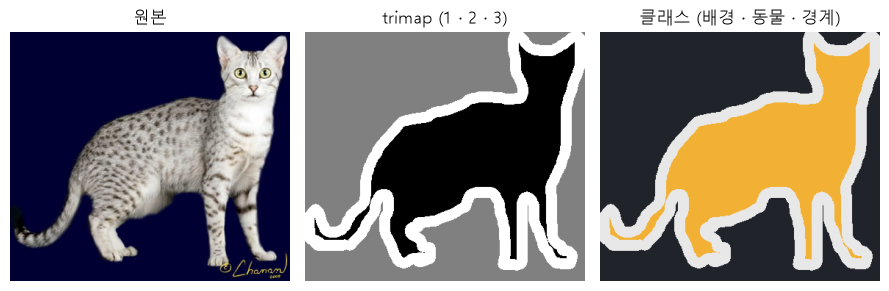

In [4]:
# [보강] 원본 1장: 크기 제각각 · trimap 값 1 동물 · 2 배경 · 3 경계
img0, tri0 = pet[int(train_idx[0])]  # 학습 첫 장 (사진, trimap)
tri0 = np.array(tri0)                # PIL → 배열
print("이미지:", img0.size, img0.mode, "| trimap:", tri0.shape, tri0.dtype,  # 크기 · 값 확인
      "| 값:", np.unique(tri0).tolist())


# trimap → 클래스 번호 (2 배경 → 0 · 1 동물 → 1 · 3 경계 → 2)
LUT = np.array([0, 1, 0, 2])                  # LUT[trimap 값] = 클래스 번호
m0 = LUT[tri0]                                # 배열로 번호 찾기 → 픽셀 전체를 한 번에 변환
print("변환 후 값:", np.unique(m0).tolist(),  # 0 · 1 · 2만 남았나
      "| 클래스별 픽셀:", np.bincount(m0.ravel(), minlength=3).tolist())


# 흔한 실수: trimap을 그대로 정답으로 → 번호 3은 클래스 3개 범위 밖
try:
    F.cross_entropy(torch.zeros(1, 3, *tri0.shape),                  # 번호 3이 있는 정답
                    torch.as_tensor(tri0[None], dtype=torch.long))
except IndexError as e:                                              # 범위 밖 번호 에러
    print("trimap 그대로 CE →", type(e).__name__, "|", str(e)[:28])  # 에러 이름 · 앞부분


# 원본 · trimap · 변환한 마스크
fig, ax = plt.subplots(1, 3, figsize=(9, 3))  # 세 칸 그림
ax[0].imshow(img0)                            # 원본 사진
ax[1].imshow(tri0, cmap="gray")               # trimap (회색조)
ax[2].imshow(m0, cmap=CMAP, vmin=0, vmax=2)   # 바꾼 클래스 마스크
for a, t in zip(ax, ["원본", "trimap (1 · 2 · 3)", "클래스 (배경 · 동물 · 경계)"]):  # 제목
    a.set_title(t)                            # 칸 제목
    a.axis("off")                             # 눈금 숨김
plt.tight_layout()                            # 간격 정리
plt.show()                                    # 그림 표시

**결과** · 예측 정답은 `IndexError` — 번호 3은 클래스 3개(0 ~ 2)의 범위 밖

- `이미지: (381, 339) RGB | trimap: (339, 381) uint8 | 값: [1, 2, 3]` — PIL 크기는 (너비, 높이), 배열 모양은 (높이, 너비) → 순서가 반대
- `변환 후 값: [0, 1, 2] | 클래스별 픽셀: [66532, 36525, 26102]` — 66532 + 36525 + 26102 = 129159 = 339 × 381, 빠진 픽셀 없음
- `trimap 그대로 CE → IndexError | Target 3 is out of bounds.` — CPU에서는 에러, GPU에서는 장치 에러로 프로그램 전체가 멈춤

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">trimap 그대로 (1 · 2 · 3)</td>
<td style="text-align: left;">번호가 1부터 시작하고 3까지 → 클래스 3개면 3이 범위 밖</td>
<td style="text-align: left;">쓰지 않음 (에러 또는 조용한 오답)</td>
</tr>
<tr>
<td style="text-align: left;"><code>LUT[trimap]</code> 표 찾기</td>
<td style="text-align: left;">값마다 새 번호를 한 번에 매핑, 반복문 없음</td>
<td style="text-align: left;">데이터셋마다 다른 라벨 번호를 0부터로 바꿀 때 (기본 선택)</td>
</tr>
<tr>
<td style="text-align: left;">경계(3)를 <code>ignore_index</code>로</td>
<td style="text-align: left;">경계 픽셀을 손실 · 지표에서 제외 (세그멘테이션-1 2-1)</td>
<td style="text-align: left;">경계가 애매해 학습에서 빼고 싶을 때 (VOC 방식)</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - 번호가 1부터인 마스크를 그대로 쓰면 3이 범위 밖 에러, 또는 `num_classes=4`로 늘려 **아무 픽셀도 없는 클래스 0**을 학습하게 됨

> ✅ **한 줄 정리** · 실제 데이터의 마스크는 먼저 값 종류를 확인하고, LUT 표로 0부터 연속된 클래스 번호로 바꾼 뒤 학습한다.

**딥러닝 코드에서는**

- `Dataset.__getitem__`에서 `mask = LUT[np.array(Image.open(path))]`
- Cityscapes
- ADE20K도 원래 번호를 학습 번호로 바꾸는 표를 씀

### 1-2. `A` 이미지와 마스크 크기 맞추기 · `bilinear` · `nearest` <sub>개념 PDF 11~15쪽 · 세그멘테이션-1 2-2 · 코드 보강</sub>

> 🎯 **이미지와 마스크를 같은 크기로 줄일 때, 왜 서로 다른 보간 방법을 써야 하는가?**

💡 **쉽게 말하면**

- 이미지는 **물감**이라 섞어도 자연스러운 중간색이 되지만, 마스크는 **번호표**라 1번과 3번을 섞어 2번을 만들면 엉뚱한 클래스가 됨.

**실행 흐름**

1. 같은 마스크를 nearest · bilinear로 128×128
2. 값 종류 비교
3. 반올림해도 생기는 가짜 동물 픽셀
4. 1000장을 올바른 방법으로 준비

**먼저 예측** · bilinear로 줄인 마스크를 반올림하면 원래 번호만 남을까? — 답은 코드 실행 결과 아래에

In [5]:
# [보강] 같은 마스크를 128×128로 줄이기: nearest vs bilinear
SIZE = 128                                                                  # 학습에 쓸 한 변 크기
m_t = torch.as_tensor(m0, dtype=torch.float32)[None, None]                  # (1, 1, H, W)
near = F.interpolate(m_t, size=(SIZE, SIZE), mode="nearest")                # 값 복사로 줄임
bili = F.interpolate(m_t, size=(SIZE, SIZE), mode="bilinear",               # 가중 평균으로 줄임
                     align_corners=False)
print("nearest  값:", near.unique().tolist())                               # 원래 번호만?
between = bili[bili != bili.round()]                                        # 정수가 아닌 값
print("bilinear 값 종류:", bili.unique().numel(), "개 | 정수 아닌 값 예:",  # 사이 값 개수
      [round(v, 2) for v in between[:3].tolist()])


# 반올림해도 원래 없던 번호가 생김: 배경(0)과 경계(2) 사이 → 1(동물)
fake = (bili.round() == 1) & (near != 1)                        # 없던 동물 픽셀
print("bilinear 반올림 후 가짜 '동물' 픽셀:", int(fake.sum()))  # 반올림해도 남는 오류


# 학습 · 검증 1000장을 128×128로 미리 준비 (이미지 bilinear · 마스크 nearest)
def load_pair(i):                                   # 사진 · 마스크 1쌍 준비
    img, tri = pet[int(i)]                          # i번 꺼내기
    img = img.resize((SIZE, SIZE), Image.BILINEAR)  # 이미지: 부드럽게
    tri = tri.resize((SIZE, SIZE), Image.NEAREST)   # 마스크: 값 복사
    return np.array(img), LUT[np.array(tri)]        # 마스크는 번호도 바꿈


start = time.time()                                                        # 준비 시간 재기
X_train, Y_train = map(np.stack, zip(*[load_pair(i) for i in train_idx]))  # 학습 800쌍
X_val, Y_val = map(np.stack, zip(*[load_pair(i) for i in val_idx]))        # 검증 200쌍
X_train = torch.tensor(X_train).permute(0, 3, 1, 2)                        # HWC → CHW, uint8
X_val = torch.tensor(X_val).permute(0, 3, 1, 2)                            # HWC → CHW
Y_train, Y_val = torch.tensor(Y_train), torch.tensor(Y_val)                # int64
print("X_train:", tuple(X_train.shape), X_train.dtype,                     # 모양 · 자료형
      "| Y_train:", tuple(Y_train.shape), Y_train.dtype)
print("X_val:", tuple(X_val.shape), "| Y_val:", tuple(Y_val.shape),        # 검증 모양 · 값
      "| 마스크 값:", Y_train.unique().tolist())
print(f"준비 시간: {time.time() - start:.1f}초")                           # 걸린 시간

nearest  값: [0.0, 1.0, 2.0]
bilinear 값 종류: 356 개 | 정수 아닌 값 예: [1.7, 1.59, 1.62]
bilinear 반올림 후 가짜 '동물' 픽셀: 256


X_train: (800, 3, 128, 128) torch.uint8 | Y_train: (800, 128, 128) torch.int64
X_val: (200, 3, 128, 128) | Y_val: (200, 128, 128) | 마스크 값: [0, 1, 2]
준비 시간: 3.8초


**결과** · 예측 정답은 아님 — 배경(0)과 경계(2) 사이가 1(동물)로 바뀌어 가짜 동물 픽셀 256개

- `nearest  값: [0.0, 1.0, 2.0]` — 원래 번호 3종만 남음
- `bilinear 값 종류: 356 개 | 정수 아닌 값 예: [1.7, 1.59, 1.62]` — 번호 사이 값이 수백 종 생김
- `bilinear 반올림 후 가짜 '동물' 픽셀: 256` — 0과 2의 중간 → 1, 동물이 없는 경계 바깥에 동물 픽셀
- `X_train: (800, 3, 128, 128) torch.uint8 | Y_train: (800, 128, 128) torch.int64` — 이미지는 uint8로 저장(메모리 ¼), 마스크는 long
- `X_val: (200, 3, 128, 128) | Y_val: (200, 128, 128) | 마스크 값: [0, 1, 2]` — 줄인 뒤에도 번호 3종 그대로

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">이미지 resize bilinear</td>
<td style="text-align: left;">이웃 픽셀 가중 평균 → 부드러움, 새 값이 생겨도 괜찮음</td>
<td style="text-align: left;"><strong>이미지</strong> 크기 맞추기 (기본 선택)</td>
</tr>
<tr>
<td style="text-align: left;">마스크 resize nearest</td>
<td style="text-align: left;">가장 가까운 값 복사 → 원래 번호만 남음</td>
<td style="text-align: left;"><strong>마스크</strong> 크기 맞추기 (항상)</td>
</tr>
<tr>
<td style="text-align: left;">마스크 resize bilinear</td>
<td style="text-align: left;">0과 2 사이에 1 같은 가짜 번호, 반올림해도 남음</td>
<td style="text-align: left;">쓰지 않음</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - `transforms.Resize`를 이미지
> - 마스크에 같은 객체로 쓰면 둘 다 bilinear
> - 마스크는 `InterpolationMode.NEAREST`를 따로 지정하거나 2-3의 `v2` + `Mask` 사용

> ✅ **한 줄 정리** · 이미지 크기 조정은 bilinear, 마스크 크기 조정은 반드시 nearest로 해야 원래 클래스 번호만 남는다.

**딥러닝 코드에서는**

- `img.resize(size, Image.BILINEAR)`
- `mask.resize(size, Image.NEAREST)`, 예측 마스크를 원본 크기로 되돌릴 때도 점수(logit)는 bilinear 후 argmax

### 1-3. `A` 이미지 · 마스크 함께 증강 · `v2` · `tv_tensors.Mask` <sub>개념 PDF 46쪽 · 세그멘테이션-1 0장 · 코드 보강</sub>

> 🎯 **자르기 · 뒤집기 증강을 할 때 이미지와 마스크의 위치가 어긋나지 않게 하려면?**

💡 **쉽게 말하면**

- 이미지와 마스크는 **같은 종이에 그린 그림과 투명 덧지**.
- 자르고 뒤집을 때 두 장을 **겹친 채로 한 번에** 해야 칸이 맞음.

**실행 흐름**

1. 위치 증강 정의
2. 마스크를 그림으로 만든 확인용 이미지
3. 함께 · 따로 증강의 일치율
4. 정규화까지 묶은 학습 · 검증 변환
5. Dataset

**먼저 예측** · 같은 변환을 이미지와 마스크에 **따로** 두 번 호출하면 일치율은? — 답은 코드 실행 결과 아래에

In [6]:
# [보강] 위치를 바꾸는 증강 (크기 · 위치 자르기 + 좌우 뒤집기)
geo_tf = v2.Compose([  # 위치를 바꾸는 증강 2개
    v2.RandomResizedCrop(SIZE, scale=(0.5, 1.0), antialias=True),
    v2.RandomHorizontalFlip(p=0.5)])


# 맞는지 확인용: 마스크를 그림(값 × 100)으로 만들어 같이 넣기
probe = tv_tensors.Image((Y_train[0] * 100).to(torch.uint8).repeat(3, 1, 1))  # 확인용 그림
mask = tv_tensors.Mask(Y_train[0])                                            # 이건 마스크라고 표시


def agree(img, m):  # 그림에서 되읽은 번호 = 마스크 번호인 비율
    return ((img[0].float() / 100).round().long() == m).float().mean().item()  # 같은 칸 비율


torch.manual_seed(0)                                                   # 증강 난수 고정
a_img, a_mask = geo_tf(probe, mask)                                    # 함께: 같은 난수로 같은 변환
b_img, b_mask = geo_tf(probe), geo_tf(mask)                            # 따로: 난수를 2번 뽑음
print("함께 증강 일치율:", round(agree(a_img, a_mask), 4))             # 거의 1
print("따로 증강 일치율:", round(agree(b_img, b_mask), 4))             # 크게 어긋남
print("함께 증강 후 마스크:", a_mask.dtype, a_mask.unique().tolist())  # 번호 그대로?


# 학습용 전체 변환: 위치 증강 → 0 ~ 1 실수 → ImageNet 정규화 (마스크는 위치만)
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]               # ImageNet 평균 · 표준편차
train_tf = v2.Compose([geo_tf, v2.ToDtype(torch.float32, scale=True),  # 증강 → 실수 → 정규화
                       v2.Normalize(MEAN, STD)])
val_tf = v2.Compose([v2.ToDtype(torch.float32, scale=True),            # 검증은 증강 없이
                     v2.Normalize(MEAN, STD)])                         # 검증은 증강 없이


class PetSeg(Dataset):                      # 이미지 · 마스크 데이터셋
    def __init__(self, X, Y, tf):           # 미리 준비한 텐서 · 변환
        self.X, self.Y, self.tf = X, Y, tf  # 저장

    def __len__(self):      # 몇 장인지
        return len(self.X)  # 800 또는 200

    def __getitem__(self, i):                                              # i번째 한 쌍
        img = tv_tensors.Image(self.X[i])                                  # 이미지라고 표시
        m = tv_tensors.Mask(self.Y[i])                                     # 마스크라고 표시
        img, m = self.tf(img, m)                                           # 같은 난수로 함께 변환
        return img.as_subclass(torch.Tensor), m.as_subclass(torch.Tensor)  # 보통 텐서로


train_set = PetSeg(X_train, Y_train, train_tf)                              # 학습용 (증강 있음)
val_set = PetSeg(X_val, Y_val, val_tf)                                      # 검증용 (증강 없음)
x, y = train_set[0]                                                         # 한 쌍 꺼내 확인
print("학습 샘플:", tuple(x.shape), x.dtype, "|", tuple(y.shape), y.dtype)  # 모양 · 자료형

함께 증강 일치율: 0.9462
따로 증강 일치율: 0.4555
함께 증강 후 마스크: torch.int64 [0, 1, 2]
학습 샘플: (3, 128, 128) torch.float32 | (128, 128) torch.int64


**결과** · 예측 정답은 0.4555 — 난수가 따로 뽑혀 절반 넘게 어긋남, 함께 넣으면 0.9462

- `함께 증강 일치율: 0.9462` — 같은 변환, 완전히 같지 않은 건 확인용 그림이 bilinear라 경계 값이 섞여서 (1-2와 같은 현상)
- `따로 증강 일치율: 0.4555` — 자르는 위치 · 뒤집기 여부가 서로 다름 → 정답이 틀린 데이터로 학습
- `함께 증강 후 마스크: torch.int64 [0, 1, 2]` — v2가 Mask를 알아보고 nearest로 처리 → 번호 그대로
- `학습 샘플: (3, 128, 128) torch.float32 | (128, 128) torch.int64` — 이미지만 실수 · 정규화, 마스크는 위치만 변환

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">함께 증강 (<code>v2</code> + <code>tv_tensors.Mask</code>)</td>
<td style="text-align: left;">난수 1번으로 이미지 · 마스크에 같은 변환, 마스크는 자동 nearest</td>
<td style="text-align: left;">위치가 바뀌는 증강 (자르기 · 뒤집기 · 회전) (기본 선택)</td>
</tr>
<tr>
<td style="text-align: left;">따로 증강 (호출 2번)</td>
<td style="text-align: left;">난수가 따로 뽑혀 이미지와 마스크 위치가 어긋남</td>
<td style="text-align: left;">쓰지 않음</td>
</tr>
<tr>
<td style="text-align: left;">이미지에만 적용</td>
<td style="text-align: left;">밝기 · 색 · 정규화처럼 위치를 안 바꾸는 변환</td>
<td style="text-align: left;"><code>ColorJitter</code> · <code>Normalize</code> (v2는 마스크를 알아서 건너뜀)</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - 위치를 바꾸는 증강을 이미지와 마스크에 따로 호출하거나 `random`으로 따로 뽑으면 에러 없이 정답이 어긋남

> ✅ **한 줄 정리** · 위치를 바꾸는 증강은 v2에 이미지와 tv_tensors.Mask를 함께 넣어 같은 난수로 변환하고, 마스크는 nearest로 처리되게 한다.

**딥러닝 코드에서는**

- `img, mask = transform(tv_tensors.Image(img), tv_tensors.Mask(mask))`
- 탐지의 상자도 `tv_tensors.BoundingBoxes`로 함께 변환

---
## 2. 클래스 불균형

> **이 장의 흐름**
>
> - 1장에서 만든 마스크는 배경 59% · 경계 11%
> - 일반 CE는 넓은 클래스 위주로 학습해 드문 경계를 놓침.
> - 세그멘테이션-1 4-2의 Dice 손실과 가중 CE를 실제 데이터에서 비교

**파이프라인 위치** · ④ 손실 · ⑥ 평가 — 클래스 가중치, 손실 3가지 비교

### 2-1. `A` 클래스 불균형과 가중 CE · `weight=` · `pixel_ce` <sub>개념 위클리 9 Q1 · 위클리 10 보충 · 코드 보강</sub>

> 🎯 **픽셀 비율이 크게 차이 날 때, 가중 CE는 손실을 어떻게 바꾸는가?**

💡 **쉽게 말하면**

- 배경 픽셀이 60%면 모델은 **대충 배경이라고 찍어도** 손실이 꽤 줄어듦.
- 가중 CE는 **드문 클래스 픽셀 하나에 더 큰 점수**를 걸어 찍기를 손해로 만듦.

<img src="images/seg2_imbalance.png" alt="픽셀 비율과 클래스 가중치" width="854">

**실행 흐름**

1. 클래스별 픽셀 비율
2. 1 / 비율 가중치
3. 펼쳐서 계산하는 pixel_ce가 같은 값인지
4. 전부 배경 예측의 CE · 가중 CE

**먼저 예측** · 모든 픽셀을 배경이라고 예측하면 일반 CE와 가중 CE 중 어느 쪽이 더 클까? — 답은 코드 실행 결과 아래에

In [7]:
# [보강] 학습 마스크 전체의 클래스별 픽셀 비율
counts = torch.bincount(Y_train.flatten(), minlength=3).double()  # 클래스별 픽셀 수
freq = counts / counts.sum()                                      # 비율
print("픽셀 비율:", [round(v, 4) for v in freq.tolist()])         # 얼마나 치우쳤나


# 가중치 = 1 / 비율 → 평균이 1이 되게 맞춤 (드문 클래스일수록 큼)
weight = 1 / freq                                                # 드물수록 큰 값
weight = (weight / weight.mean()).float()                        # 평균 1로 맞춤
print("클래스 가중치:", [round(v, 4) for v in weight.tolist()])  # 경계가 가장 큼


# GPU에서도 결정적인 CE: 픽셀을 펼쳐 (N·H·W, C)로 계산 (값은 같음)
def pixel_ce(logits, target, weight=None):                             # GPU에서도 결정적인 픽셀 CE
    c = logits.shape[1]                                                # 클래스 수
    return F.cross_entropy(logits.permute(0, 2, 3, 1).reshape(-1, c),  # (N·H·W, C)로 펼침
                           target.reshape(-1), weight=weight)


g = torch.Generator().manual_seed(SEED)                                      # 이 셀 전용 난수
logits = torch.randn(4, 3, SIZE, SIZE, generator=g)                          # 무작위 점수
target = Y_train[:4]                                                         # 정답 4장
print("F.cross_entropy:", round(F.cross_entropy(logits, target).item(), 4),  # 두 값 비교
      "| pixel_ce:", round(pixel_ce(logits, target).item(), 4))


# 모든 픽셀을 배경이라고 자신 있게 예측 → 정확도는 높지만
all_bg = torch.zeros(4, 3, SIZE, SIZE)     # 전부 배경이라고 찍는 예측
all_bg[:, 0] = 5.0                         # 배경 점수만 높게
acc = (target == 0).float().mean().item()  # 그래도 맞는 비율
print(f"전부 배경: 픽셀 정확도 {acc:.4f}"  # 정확도 · CE · 가중 CE
      f" | CE {pixel_ce(all_bg, target).item():.4f}"
      f" | 가중 CE {pixel_ce(all_bg, target, weight).item():.4f}")

픽셀 비율: [0.5921, 0.2956, 0.1123]
클래스 가중치: [0.3626, 0.7263, 1.9111]
F.cross_entropy: 1.3927 | pixel_ce: 1.3927
전부 배경: 픽셀 정확도 0.6687 | CE 1.6697 | 가중 CE 3.0262


**결과** · 예측 정답은 가중 CE — 3.0262 vs 1.6697, 틀린 동물 · 경계 픽셀에 큰 가중치

- `픽셀 비율: [0.5921, 0.2956, 0.1123]` — 배경 59% · 동물 30% · 경계 11% (경계가 가장 드묾)
- `클래스 가중치: [0.3626, 0.7263, 1.9111]` — 1 / 비율을 평균 1로 맞춤 → 경계 픽셀 1개 = 배경 픽셀 약 5개 몫
- `F.cross_entropy: 1.3927 | pixel_ce: 1.3927` — 펼쳐서 계산해도 같은 값 (GPU 재현용)
- `전부 배경: 픽셀 정확도 0.6687 | CE 1.6697 | 가중 CE 3.0262` — 정확도 67%인 찍기를 가중 CE가 더 크게 벌함

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">일반 CE</td>
<td style="text-align: left;">픽셀마다 같은 비중 → 넓은 배경 위주</td>
<td style="text-align: left;">클래스 비율이 비슷할 때</td>
</tr>
<tr>
<td style="text-align: left;">가중 CE <code>weight=</code></td>
<td style="text-align: left;">드문 클래스 픽셀에 큰 가중치 → 클래스마다 비슷한 비중</td>
<td style="text-align: left;">불균형 대응의 첫 시도 (간단 · 안정)</td>
</tr>
<tr>
<td style="text-align: left;"><code>F.cross_entropy(logits, mask)</code></td>
<td style="text-align: left;">(N, C, H, W) 그대로, GPU에서 결정적 구현 없음</td>
<td style="text-align: left;">재현성이 필요 없을 때 (보통 코드)</td>
</tr>
<tr>
<td style="text-align: left;"><code>pixel_ce</code> (펼쳐서)</td>
<td style="text-align: left;">(N·H·W, C)로 펼쳐 같은 값, GPU에서도 결정적</td>
<td style="text-align: left;">seed로 결과를 똑같이 재현해야 할 때 (이 노트북)</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - 가중치를 데이터 전체가 아니라 배치마다 다시 계산하면 손실 척도가 배치마다 흔들림
> - 학습 데이터 전체로 한 번만 계산

> ✅ **한 줄 정리** · 가중 CE는 드문 클래스 픽셀에 큰 가중치를 곱해, 넓은 클래스만 맞히는 예측을 손해로 만든다.

**딥러닝 코드에서는**

- `nn.CrossEntropyLoss(weight=w.to(device))`
- GPU에서 결과를 똑같이 재현해야 하면 `(N, C, H, W)`를 펼쳐 계산 (이 노트북의 `pixel_ce`)

### 2-2. `B` 일반 CE vs 가중 CE vs Dice · `pixel_ce` · `weight` · `dice_loss` <sub>개념 위클리 9 Q1 · 위클리 10 보충 · 세그멘테이션-1 4-2 · 코드 보강</sub>

> 🎯 **손실만 바꿔 같은 U-Net을 학습하면, 가장 드문 경계 클래스의 IoU는 어떻게 달라지는가?**

💡 **쉽게 말하면**

- 같은 학생 · 같은 문제집에 **채점 기준만** 바꿔 본 실험.
- 픽셀 개수대로 채점(CE), 드문 문제 배점 올리기(가중 CE), 과목별 점수(Dice).

**실행 흐름**

1. 학습 · 평가 함수 정의
2. 손실 3가지로 U-Net 4 epoch씩
3. 픽셀 정확도 · mIoU · 경계 IoU 비교

**먼저 예측** · 픽셀 정확도가 가장 높은 손실이 경계 IoU도 가장 높을까? — 답은 코드 실행 결과 아래에

In [8]:
# [보강] 학습 · 평가 함수 (2-2 · 3-2 · 5장에서 같이 사용)
BATCH = 16                                       # 배치 크기
val_loader = DataLoader(val_set, batch_size=64)  # 검증은 섞지 않음


def forward(model, x):  # torchvision 분할 모델은 dict, U-Net은 텐서
    out = model(x)      # 모델 실행
    return out["out"] if isinstance(out, dict) else out  # 분할 점수만


def train(build, loss_fn, epochs, lr):                 # 같은 조건 학습 (2-2 · 3-2 · 5장)
    set_seed()                                         # 초기값 · 섞는 순서 · 증강 난수까지 같게
    model = build().to(device)                         # seed 직후 생성 → 같은 초기값
    opt = torch.optim.Adam(model.parameters(), lr=lr)  # 최적화
    loader = DataLoader(train_set, batch_size=BATCH, shuffle=True,  # 같은 섞는 순서
                        generator=torch.Generator().manual_seed(SEED))
    start = time.time()                                # 학습 시간 재기
    for epoch in range(epochs):                        # epoch 반복
        model.train()                                  # BatchNorm 학습 모드
        for x, y in loader:                            # 배치마다
            x, y = x.to(device), y.to(device)          # GPU로
            loss = loss_fn(forward(model, x), y)       # 바꿔 끼울 손실
            opt.zero_grad()                            # 이전 기울기 지우기
            loss.backward()                            # 기울기 계산
            opt.step()                                 # 가중치 갱신
    return model, time.time() - start                  # 모델 · 걸린 초


@torch.no_grad()
def evaluate(model):                                                    # 검증 200장 지표
    model.eval()                                                        # BatchNorm 평가 모드
    pred = torch.cat([forward(model, x.to(device)).argmax(dim=1).cpu()  # 예측 마스크 모으기
                      for x, _ in val_loader])
    return pred, seg_metrics(pred, Y_val)                               # 예측 · 지표


# 손실만 바꿔 같은 U-Net을 4 epoch씩 학습
losses = {"일반 CE": lambda o, y: pixel_ce(o, y),                      # 비교할 손실 3가지
          "가중 CE": lambda o, y: pixel_ce(o, y, weight.to(device)),
          "Dice": dice_loss}
for name, fn in losses.items():                                        # 손실마다
    model, sec = train(UNet, fn, epochs=4, lr=1e-3)                    # 같은 U-Net · 같은 조건
    _, (acc, iou, dice) = evaluate(model)                              # 검증 지표
    ious = [round(v, 4) for v in iou.tolist()]                         # 클래스별 IoU
    print(f"{name:6} | 픽셀 정확도 {acc:.4f} | mIoU {iou.mean():.4f}"  # 결과 한 줄
          f" | 경계 IoU {iou[2]:.4f} | IoU {ious}")

일반 CE  | 픽셀 정확도 0.7541 | mIoU 0.4801 | 경계 IoU 0.1763 | IoU [0.7422, 0.5219, 0.1763]


가중 CE  | 픽셀 정확도 0.7363 | mIoU 0.5306 | 경계 IoU 0.2921 | IoU [0.6988, 0.6009, 0.2921]


Dice   | 픽셀 정확도 0.7678 | mIoU 0.5269 | 경계 IoU 0.2894 | IoU [0.764, 0.5274, 0.2894]


**결과** · 예측 정답은 아님 — 픽셀 정확도는 Dice가 가장 높지만, 경계 IoU는 가중 CE(0.2921)가 가장 높고 일반 CE(0.1763)가 가장 낮음

- `일반 CE  | 픽셀 정확도 0.7541 | mIoU 0.4801 | 경계 IoU 0.1763` — 넓은 배경 위주 → 경계를 거의 못 맞힘
- `가중 CE  | 픽셀 정확도 0.7363 | mIoU 0.5306 | 경계 IoU 0.2921` — 경계 IoU 1.7배, 배경 IoU는 조금 손해 (0.7422 → 0.6988)
- `Dice   | 픽셀 정확도 0.7678 | mIoU 0.5269 | 경계 IoU 0.2894` — 경계를 가중 CE만큼 올리면서 배경도 유지

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">일반 CE</td>
<td style="text-align: left;">학습이 안정적, 작은 클래스(경계)는 덜 맞힘</td>
<td style="text-align: left;">기본 출발점</td>
</tr>
<tr>
<td style="text-align: left;">가중 CE</td>
<td style="text-align: left;">작은 클래스를 더 맞히지만 큰 클래스가 조금 손해 볼 수 있음</td>
<td style="text-align: left;">작은 클래스의 재현이 중요할 때</td>
</tr>
<tr>
<td style="text-align: left;">Dice 손실</td>
<td style="text-align: left;">클래스마다 겹침 비율 → 작은 클래스에 강함, 초반이 불안정할 수 있음</td>
<td style="text-align: left;">의료 영상처럼 아주 작은 대상</td>
</tr>
<tr>
<td style="text-align: left;">CE + Dice</td>
<td style="text-align: left;">둘을 더해 안정성과 작은 클래스 보정을 같이</td>
<td style="text-align: left;">실무에서 흔한 조합</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - 4 epoch
> - 1회 실험이라 가중 CE와 Dice의 순위(0.5306 vs 0.5269)는 바뀔 수 있음
> - 결론은 "일반 CE보다 둘 다 경계에 강하다"까지

> ✅ **한 줄 정리** · 불균형이 심하면 일반 CE는 드문 클래스를 놓치기 쉬우므로, 가중 CE나 Dice 손실로 드문 클래스의 비중을 키운다.

**딥러닝 코드에서는**

- `loss = pixel_ce(out, y, w) + dice_loss(out, y)`처럼 섞어 쓰는 경우도 많음
- 비교할 때는 이 셀처럼 **손실 하나만** 바꿈

---
## 3. 사전학습 분할 모델

> **이 장의 흐름**
>
> - 2장 U-Net은 처음부터 배워 경계 IoU가 0.3 아래였다
> - 수많은 사진으로 이미 학습된 FCN · DeepLabV3를 가져와 마지막 층만 바꿔 미세조정

**파이프라인 위치** · ③ 모델 구조 · ⑤ 학습 — 사전학습 가중치, 분류기 교체, 미세조정

### 3-1. `A` 사전학습 분할 모델과 분류기 교체 · `deeplabv3_resnet50` · `classifier[4]` <sub>개념 위클리 9 Q2 보충 · 위클리 10 · 코드 보강</sub>

> 🎯 **사전학습 DeepLabV3 · FCN은 무엇을 출력하며, 우리 클래스(3개)에 맞추려면 어디를 바꾸는가?**

💡 **쉽게 말하면**

- 사전학습 모델은 **21과목을 배운 졸업생**.
- 우리 시험은 3과목이라 **마지막 답안지(1×1 합성곱)만 3칸짜리로 바꿔 끼우고** 나머지 실력은 그대로 씀.

<img src="images/seg2_models.png" alt="U-Net · FCN · DeepLabV3 구조" width="912">

**실행 흐름**

1. 가중치 · 클래스 목록
2. 그대로 추론(강아지를 알아보나)
3. 마지막 층을 21에서 3으로 교체 · 보조 출력 끄기
4. 세 모델 크기 · 머리 구조 비교

**먼저 예측** · Oxford Pet을 본 적 없는 사전학습 DeepLabV3가 검증 강아지 사진을 그대로 추론하면? — 답은 코드 실행 결과 아래에

In [9]:
# [보강] COCO(VOC 21클래스)로 사전학습한 DeepLabV3 · FCN 불러오기
DL_W = segmentation.DeepLabV3_ResNet50_Weights.DEFAULT          # DeepLabV3 사전학습 가중치
FCN_W = segmentation.FCN_ResNet50_Weights.DEFAULT               # FCN 사전학습 가중치
cats = DL_W.meta["categories"]                                  # 사전학습 클래스 이름
print("사전학습 클래스:", len(cats), "개 | 앞 5개:", cats[:5])  # 21개 확인


# 1. 그대로 추론: 강아지 · 고양이를 VOC 클래스로 알아보나
dl = segmentation.deeplabv3_resnet50(weights=DL_W).eval()                     # 그대로 추론용
x0 = val_tf(tv_tensors.Image(X_val[0]))[None]                                 # (1, 3, 128, 128)
with torch.no_grad():                                                         # 추론은 기울기 불필요
    out = dl(x0)                                                              # 검증 첫 장 추론
print("출력 키:", list(out.keys()), "| out:", tuple(out["out"].shape))        # dict 출력
found = out["out"].argmax(dim=1).flatten().bincount(minlength=len(cats))      # 클래스별 픽셀
print("예측된 클래스:", {cats[i]: int(n) for i, n in enumerate(found) if n})  # 나온 것만


# 2. 분류기 교체: 마지막 1×1 합성곱 21 → 3 (배경 · 동물 · 경계)
print("DeepLabV3 마지막 층:", dl.classifier[4])               # 바꿀 층 확인
dl.classifier[4] = nn.Conv2d(256, 3, kernel_size=1)           # 21 → 3 클래스
dl.aux_classifier = None                                      # 보조 출력은 쓰지 않음
fcn = segmentation.fcn_resnet50(weights=FCN_W)                # FCN도 불러오기
print("FCN 마지막 층      :", fcn.classifier[4])              # 바꿀 층 확인
fcn.classifier[4] = nn.Conv2d(512, 3, kernel_size=1)          # 21 → 3 클래스
fcn.aux_classifier = None                                     # 보조 출력 끔
with torch.no_grad():                                         # 추론은 기울기 불필요
    print("교체 후 out:", tuple(dl.eval()(x0)["out"].shape),  # 채널 3 확인
          tuple(fcn.eval()(x0)["out"].shape))


# 3. 구조 비교: 파라미터 수 (백만 단위)
def n_param(m):                                          # 파라미터 수 (백만 단위)
    return sum(p.numel() for p in m.parameters()) / 1e6  # ÷ 100만


print(f"파라미터 · U-Net {n_param(UNet()):.2f}M | FCN {n_param(fcn):.2f}M"  # 크기 비교
      f" | DeepLabV3 {n_param(dl):.2f}M")
print("DeepLabV3 머리 첫 층:", type(dl.classifier[0]).__name__,             # ASPP vs Conv2d
      "| FCN 머리 첫 층:", type(fcn.classifier[0]).__name__)

사전학습 클래스: 21 개 | 앞 5개: ['__background__', 'aeroplane', 'bicycle', 'bird', 'boat']


출력 키: ['out', 'aux'] | out: (1, 21, 128, 128)
예측된 클래스: {'__background__': 9206, 'dog': 7178}
DeepLabV3 마지막 층: Conv2d(256, 21, kernel_size=(1, 1), stride=(1, 1))


FCN 마지막 층      : Conv2d(512, 21, kernel_size=(1, 1), stride=(1, 1))


교체 후 out: (1, 3, 128, 128) (1, 3, 128, 128)
파라미터 · U-Net 0.48M | FCN 32.95M | DeepLabV3 39.63M
DeepLabV3 머리 첫 층: ASPP | FCN 머리 첫 층: Conv2d


**결과** · 예측 정답은 VOC 클래스 `dog`로 7178픽셀을 칠함 — 이미 강아지를 앎

- `사전학습 클래스: 21 개 | 앞 5개: ['__background__', 'aeroplane', 'bicycle', 'bird', 'boat']` — COCO 이미지를 VOC 20클래스 + 배경으로 학습
- `출력 키: ['out', 'aux'] | out: (1, 21, 128, 128)` — dict 출력, `out`이 (N, C, H, W) 분할 점수 (aux = 학습 보조 출력)
- `예측된 클래스: {'__background__': 9206, 'dog': 7178}` — 9206 + 7178 = 16384 = 128 × 128, 배경 · 강아지만
- `DeepLabV3 마지막 층: Conv2d(256, 21, kernel_size=(1, 1), stride=(1, 1))` — 바꿀 곳: 256채널 → 21클래스 1×1 합성곱
- `FCN 마지막 층      : Conv2d(512, 21, kernel_size=(1, 1), stride=(1, 1))` — FCN은 512채널에서 바로 21클래스
- `교체 후 out: (1, 3, 128, 128) (1, 3, 128, 128)` — 출력 채널만 3으로, 크기는 입력과 같음
- `파라미터 · U-Net 0.48M | FCN 32.95M | DeepLabV3 39.63M` — 사전학습 모델은 U-Net의 약 70 ~ 80배 (ResNet-50 백본)
- `DeepLabV3 머리 첫 층: ASPP | FCN 머리 첫 층: Conv2d` — DeepLabV3만 여러 크기 문맥을 모으는 ASPP

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">U-Net</td>
<td style="text-align: left;">대칭 인코더-디코더 + skip <strong>이어 붙이기</strong>, 보통 처음부터 학습</td>
<td style="text-align: left;">데이터가 적고 경계가 중요한 분야 (의료)</td>
</tr>
<tr>
<td style="text-align: left;">FCN</td>
<td style="text-align: left;">ResNet 백본 → 3×3 합성곱 머리 → 한 번에 bilinear 업샘플</td>
<td style="text-align: left;">가장 단순한 사전학습 분할 기준선</td>
</tr>
<tr>
<td style="text-align: left;">DeepLabV3</td>
<td style="text-align: left;">ResNet 백본 + <strong>ASPP</strong>(팽창 합성곱 여러 개 + 전체 평균)로 여러 크기 문맥</td>
<td style="text-align: left;">크기가 다양한 물체가 있는 사진 (기본 선택)</td>
</tr>
<tr>
<td style="text-align: left;">분류기 교체</td>
<td style="text-align: left;">마지막 1×1 합성곱만 새 클래스 수로, 나머지 가중치는 그대로</td>
<td style="text-align: left;">사전학습 분할 모델을 내 클래스에 맞출 때</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - 분류기만 바꾸고 `aux_classifier`를 그대로 두면 `aux` 출력이 여전히 21채널
> - 쓰지 않으면 `None`, 쓰면 같이 바꾸기

> ✅ **한 줄 정리** · 사전학습 분할 모델은 마지막 1×1 합성곱만 우리 클래스 수로 바꾸면 나머지 가중치를 그대로 활용할 수 있다.

**딥러닝 코드에서는**

- `model.classifier[4] = nn.Conv2d(256, num_classes, 1)` → `model(x)["out"]`
- torchvision 분할 모델은 출력이 dict

### 3-2. `A` 처음부터 학습 vs 사전학습 미세조정 · `weights=None` · `weights=DEFAULT` <sub>개념 위클리 9 Q2 (FCN 전이 학습) · 코드 보강</sub>

> 🎯 **같은 DeepLabV3 구조를 같은 조건으로 2 epoch 학습할 때, 사전학습 가중치에서 시작하면 얼마나 달라지는가?**

💡 **쉽게 말하면**

- 처음부터 학습은 **글자도 모르는 아이에게 시험 범위만 주는 것**, 미세조정은 **이미 읽을 줄 아는 사람에게 범위만 알려 주는 것**.
- 같은 2시간이면 결과가 다름.

**실행 흐름**

1. 사전학습 여부만 다른 deeplab() 함수
2. 같은 데이터 · lr 0.0001 · 2 epoch
3. 픽셀 정확도 · mIoU · 동물 IoU

**먼저 예측** · 2 epoch만 학습하면 두 모델의 mIoU 차이는 클까? — 답은 코드 실행 결과 아래에

In [10]:
# [보강] 모델 만드는 함수: 사전학습 여부만 다른 DeepLabV3
def deeplab(pretrained=True):                           # 사전학습 여부만 다른 모델
    m = segmentation.deeplabv3_resnet50(                # 같은 구조
        weights=DL_W if pretrained else None,
        weights_backbone=None)                          # False면 백본(ResNet)까지 완전 무작위
    m.classifier[4] = nn.Conv2d(256, 3, kernel_size=1)  # 21 → 3
    m.aux_classifier = None                             # 보조 출력 끔
    return m                                            # 완성된 모델


# 같은 구조 · 같은 데이터 · 같은 lr · 2 epoch
for pretrained in [False, True]:                                     # 처음부터 → 미세조정
    model, sec = train(lambda: deeplab(pretrained), pixel_ce,        # 같은 조건 학습
                       epochs=2, lr=1e-4)
    _, (acc, iou, dice) = evaluate(model)                            # 검증 지표
    name = "사전학습 미세조정" if pretrained else "처음부터 학습  "  # 출력 이름
    print(f"{name} | 픽셀 정확도 {acc:.4f} | mIoU {iou.mean():.4f}"  # 결과 한 줄
          f" | 동물 IoU {iou[1]:.4f}")

처음부터 학습   | 픽셀 정확도 0.6990 | mIoU 0.3964 | 동물 IoU 0.4648


사전학습 미세조정 | 픽셀 정확도 0.8890 | mIoU 0.6942 | 동물 IoU 0.8101


**결과** · 예측 정답은 큼 — 0.3964 vs 0.6942, 동물 IoU는 0.4648 vs 0.8101

- `처음부터 학습   | 픽셀 정확도 0.6990 | mIoU 0.3964 | 동물 IoU 0.4648` — 무작위 가중치 → 2 epoch로는 아직 윤곽만
- `사전학습 미세조정 | 픽셀 정확도 0.8890 | mIoU 0.6942 | 동물 IoU 0.8101` — 같은 구조 · 같은 시간인데 mIoU 0.2978 높음

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">처음부터 학습</td>
<td style="text-align: left;">가중치 무작위 → 데이터 · epoch가 많이 필요</td>
<td style="text-align: left;">사전학습 모델이 없는 영역 · 입력 (위성 다채널 등)</td>
</tr>
<tr>
<td style="text-align: left;">사전학습 미세조정</td>
<td style="text-align: left;">이미 아는 특징에서 출발 → 적은 데이터 · 짧은 학습</td>
<td style="text-align: left;">일반 사진 분할 (기본 선택)</td>
</tr>
<tr>
<td style="text-align: left;">백본 고정 + 머리만</td>
<td style="text-align: left;"><code>requires_grad=False</code>로 백본을 얼림 → 빠르고 과적합 적음</td>
<td style="text-align: left;">데이터가 아주 적을 때의 첫 단계</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - 사전학습 모델에는 학습 때와 같은 정규화(ImageNet 평균 · 표준편차)를 넣어야 함
> - 빼면 미세조정 효과가 크게 줄어듦 (1-3 `Normalize`)

> ✅ **한 줄 정리** · 같은 구조라도 사전학습 가중치에서 시작하면 적은 데이터 · 짧은 학습으로 처음부터 학습보다 훨씬 높은 성능에 도달한다.

**딥러닝 코드에서는**

- `deeplabv3_resnet50(weights=DeepLabV3_ResNet50_Weights.DEFAULT)` + 작은 lr(1e-4)
- 데이터가 아주 적으면 `for p in model.backbone.parameters(): p.requires_grad = False`부터

---
## 4. Instance · Panoptic

> **이 장의 흐름**
>
> - 1 ~ 3장은 픽셀마다 클래스만 맞혔다
> - 동물이 두 마리면 몇 마리인지 모름.
> - 개체마다 마스크를 내는 Mask R-CNN과, 배경까지 한 장에 합친 파놉틱

**파이프라인 위치** · ② 출력 정하기 · ⑥ 평가 — 개체 목록, (클래스, ID) 지도

### 4-1. `A` Mask R-CNN 인스턴스 분할 추론 · `maskrcnn_resnet50_fpn` · `masks` <sub>개념 PDF 44~62쪽 · 위클리 10 · 코드 보강</sub>

> 🎯 **Mask R-CNN은 개체마다 무엇을 출력하며, 탐지 박스와 인스턴스 마스크는 어떻게 다른가?**

💡 **쉽게 말하면**

- 탐지는 동물마다 **상자를 두르는 것**, 인스턴스 분할은 동물마다 **윤곽대로 오려 낸 스티커**를 주는 것.
- 상자 안에는 배경이 섞이지만 스티커에는 동물만.

**실행 흐름**

1. 강아지 · 고양이 사진을 이어 붙인 장면
2. COCO 사전학습 Mask R-CNN 추론
3. 신뢰도 0.5 · 마스크 0.5 기준
4. 박스 vs 마스크 넓이 · 정답과 IoU
5. 겹친 마스크 확인

**먼저 예측** · 동물 2마리 장면에서 신뢰도 0.5를 넘는 개체는 몇 개일까? — 답은 코드 실행 결과 아래에

In [11]:
# [보강] 검증 사진 2장을 이어 붙여 동물 2마리 장면 만들기
a, b = 0, 7                                     # 검증 번호 (0 강아지 · 7 고양이)
scene = torch.cat([X_val[a], X_val[b]], dim=2)  # (3, 128, 256) uint8
gt = torch.cat([Y_val[a], Y_val[b]], dim=1)     # 정답 (128, 256)


# COCO로 학습한 Mask R-CNN (Oxford Pet은 본 적 없음) 추론
MR_W = detection.MaskRCNN_ResNet50_FPN_Weights.DEFAULT                     # COCO 사전학습 가중치
mrcnn = detection.maskrcnn_resnet50_fpn(weights=MR_W).eval().to(device)    # 추론 모드 · GPU
with torch.no_grad():                                                      # 추론은 기울기 불필요
    det = mrcnn([MR_W.transforms()(scene).to(device)])[0]                  # 리스트 → dict
det = {k: v.cpu() for k, v in det.items()}                                 # 결과를 CPU로
print("출력 키:", list(det.keys()))                                        # 4종 출력
keep = det["scores"] > 0.5                                                 # 신뢰도 0.5 넘는 개체만
names = [MR_W.meta["categories"][i] for i in det["labels"][keep]]          # 번호 → 이름
masks = det["masks"][keep, 0] > 0.5  # (N, 1, H, W) 확률 → (N, H, W) bool
boxes = det["boxes"][keep]                                                 # 남긴 개체의 상자
scores = [round(s, 3) for s in det["scores"][keep].tolist()]               # 점수 3자리
print("개체:", names, "| 점수:", scores)                                   # 개체 목록
print("masks:", tuple(det["masks"][keep].shape), "→", tuple(masks.shape))  # 확률 → 참/거짓


# 박스 vs 마스크: 박스 안에서 동물이 아닌 픽셀 비율 · 정답과 IoU
pet_area = gt != 0                                                # 정답의 동물 + 경계
for name, m, (x1, y1, x2, y2) in zip(names, masks, boxes.int().tolist()):  # 개체마다
    box_area = (x2 - x1) * (y2 - y1)                              # 상자 넓이
    side = slice(0, 128) if x1 + x2 < 256 else slice(128, 256)    # 박스 중심
    t = torch.zeros_like(pet_area)                                # 그 사진 쪽 정답만 남길 판
    t[:, side] = pet_area[:, side]                                # 왼쪽 또는 오른쪽 정답
    iou = (m & t).sum() / (m | t).sum()                           # 마스크 vs 정답 IoU
    print(f"{name}: 박스 {box_area}px | 마스크 {int(m.sum())}px"  # 박스 · 마스크 비교
          f" | 박스 안 배경 {1 - m.sum().item() / box_area:.2f}"
          f" | 정답과 IoU {iou:.4f}")


# 마스크끼리 겹침: 같은 동물에 클래스가 다른 마스크가 2개 나올 수 있음
inter = (masks[:, None] & masks[None]).flatten(2).sum(-1).float()    # 마스크 쌍 교집합
union = (masks[:, None] | masks[None]).flatten(2).sum(-1).float()    # 마스크 쌍 합집합
m_iou = inter / union                                                # (N, N) 마스크끼리 IoU
for i in range(len(names)):                                          # 모든 쌍
    for j in range(i + 1, len(names)):                               # 같은 쌍 두 번 안 보게
        if m_iou[i, j] > 0.5:                                        # 절반 넘게 겹치면
            print(f"겹친 마스크: {names[i]}({i}) · {names[j]}({j})"  # 중복 후보
                  f" | 마스크 IoU {m_iou[i, j]:.4f}")

출력 키: ['boxes', 'labels', 'scores', 'masks']
개체: ['cat', 'dog', 'dog'] | 점수: [0.967, 0.904, 0.505]
masks: (3, 1, 128, 256) → (3, 128, 256)
cat: 박스 8428px | 마스크 5857px | 박스 안 배경 0.31 | 정답과 IoU 0.8996
dog: 박스 7888px | 마스크 5831px | 박스 안 배경 0.26 | 정답과 IoU 0.6519
dog: 박스 9408px | 마스크 5886px | 박스 안 배경 0.37 | 정답과 IoU 0.9065
겹친 마스크: cat(0) · dog(2) | 마스크 IoU 0.9809


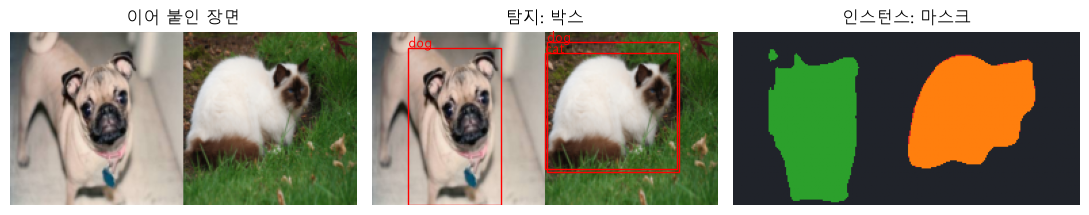

In [12]:
# [보강] 원본 · 박스 · 마스크 그림
fig, ax = plt.subplots(1, 3, figsize=(11, 2.8))                               # 세 칸 그림
ax[0].imshow(scene.permute(1, 2, 0))                                          # 이어 붙인 장면
ax[1].imshow(scene.permute(1, 2, 0))                                          # 같은 장면 위에 상자
for name, (x1, y1, x2, y2) in zip(names, boxes.tolist()):                     # 상자마다
    ax[1].add_patch(plt.Rectangle((x1, y1), x2 - x1, y2 - y1,                 # 빨간 테두리
                                  fill=False, color="red"))
    ax[1].text(x1, y1, name, color="red")                                     # 클래스 이름
inst_map = torch.zeros(gt.shape, dtype=torch.long)                            # 개체 번호 지도
for k, m in enumerate(masks, start=1):                                        # 개체 1번부터
    inst_map[m & (inst_map == 0)] = k  # 겹치면 먼저 나온(점수 높은) 개체
ax[2].imshow(inst_map, cmap=ListedColormap(["#20232a", "#ff7f0e", "#2ca02c",  # 개체별 색
                                            "#d62728"]), vmin=0, vmax=3)
for a_, t in zip(ax, ["이어 붙인 장면", "탐지: 박스", "인스턴스: 마스크"]):   # 제목
    a_.set_title(t)                                                           # 칸 제목
    a_.axis("off")                                                            # 눈금 숨김
plt.tight_layout()                                                            # 간격 정리
plt.show()                                                                    # 그림 표시

**결과** · 예측 정답은 3개 — 고양이 한 마리에 `cat`(0.967)과 `dog`(0.505) 마스크가 겹쳐 2개 나옴

- `출력 키: ['boxes', 'labels', 'scores', 'masks']` — 이미지마다 dict, 개체 N개의 상자 · 클래스 · 점수 · 마스크
- `개체: ['cat', 'dog', 'dog'] | 점수: [0.967, 0.904, 0.505]` — 점수 높은 순서, 마지막은 기준을 겨우 넘은 중복
- `masks: (3, 1, 128, 256) → (3, 128, 256)` — 개체마다 확률 지도 1장 → 0.5 기준으로 True/False
- `cat: 박스 8428px | 마스크 5857px | 박스 안 배경 0.31 | 정답과 IoU 0.8996` — 상자의 31%는 배경, 마스크는 정답과 IoU 0.90
- `dog: 박스 7888px | 마스크 5831px | 박스 안 배경 0.26 | 정답과 IoU 0.6519` — 퍼그 · 다리 일부를 놓쳐 IoU가 낮음
- `겹친 마스크: cat(0) · dog(2) | 마스크 IoU 0.9809` — 같은 고양이를 두 클래스로 → 클래스마다 따로 하는 NMS가 못 지움

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">객체 탐지 박스</td>
<td style="text-align: left;">개체마다 (x1, y1, x2, y2), 박스 안 배경이 섞임</td>
<td style="text-align: left;">위치 · 개수만 필요할 때 (라벨링 · 추론이 쌈)</td>
</tr>
<tr>
<td style="text-align: left;">인스턴스 마스크</td>
<td style="text-align: left;">개체마다 픽셀 마스크, 정확한 모양 · 넓이</td>
<td style="text-align: left;">모양 · 넓이 · 겹친 개체 분리가 필요할 때</td>
</tr>
<tr>
<td style="text-align: left;">Mask R-CNN</td>
<td style="text-align: left;">Faster R-CNN 탐지 + 박스마다 작은 FCN 마스크 머리 (RoIAlign)</td>
<td style="text-align: left;">인스턴스 분할의 표준 (torchvision 기본 제공)</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - 인스턴스 출력의 개수를 그대로 개체 수로 세면 중복이 섞일 수 있음 (위클리 10 정정: 겹친 같은 장면은 대표적인 실패 사례) · 점수 기준
> - 중복 정리가 필요

> ✅ **한 줄 정리** · Mask R-CNN은 개체마다 (상자, 클래스, 점수, 마스크)를 내며, 마스크는 상자보다 정확한 모양을 주지만 개체끼리 겹칠 수 있다.

**딥러닝 코드에서는**

- `out = model([img])[0]` → `out["masks"][out["scores"] > 0.5, 0] > 0.5`
- 입력은 텐서 **리스트**, 마스크는 확률이라 기준값으로 자름

### 4-2. `B` 의미 · 인스턴스 · 파놉틱 출력 · `(H, W)` · `N개 목록` · `(클래스, ID)` <sub>개념 PDF 4 · 50~51쪽 · 위클리 10 · 코드 보강</sub>

> 🎯 **같은 장면을 의미 · 인스턴스 · 파놉틱으로 나타내면 출력 형식과 개체 수는 어떻게 다른가?**

💡 **쉽게 말하면**

- 의미 분할은 **색칠 공부 한 장**, 인스턴스는 **스티커 묶음**(겹칠 수 있고 배경 스티커는 없음), 파놉틱은 **모든 칸에 "무엇 · 몇 번"을 적은 한 장**.

<img src="images/seg2_outputs.png" alt="의미 · 인스턴스 · 파놉틱 출력 형식" width="1094">

**실행 흐름**

1. 4-1 마스크로 ① 의미 지도 · ② 인스턴스 목록 · ③ 파놉틱 지도(점수 순서로 칠하고 절반 넘게 겹치면 버림)
2. 개체 수 비교

**먼저 예측** · 인스턴스 3개를 파놉틱 지도로 합치면 개체 ID는 몇 개가 될까? — 답은 코드 실행 결과 아래에

In [13]:
# [보강] 같은 장면의 세 가지 출력: 의미 · 인스턴스 · 파놉틱
# ① 의미 분할: 픽셀마다 클래스 (동물 = 1, 개체 구분 없음)
semantic = (masks.any(dim=0)).long()  # 마스크를 합치면 동물 영역
print("① 의미   :", tuple(semantic.shape), "| 값:", semantic.unique().tolist())  # 지도 1장


# ② 인스턴스 분할: 개체 N개의 (클래스, 마스크, 점수), 배경은 출력 없음
overlap = (masks.sum(dim=0) > 1).sum().item()                             # 두 마스크가 겹친 픽셀
print("② 인스턴스:", len(names), "개 |", names, "| 겹친 픽셀:", overlap,  # 목록 · 겹침
      "| 어느 마스크에도 없는 픽셀:", int((~masks.any(dim=0)).sum()))


# ③ 파놉틱: 모든 픽셀에 (클래스, 개체 ID) 정확히 하나 (위클리 10 합치기 규칙)
pan_class = torch.zeros(gt.shape, dtype=torch.long)                  # 0 = 배경(stuff)
pan_id = torch.zeros(gt.shape, dtype=torch.long)                     # 0 = 개체 없음
for name, m in zip(names, masks):                                    # 점수 높은 개체부터
    free = m & (pan_id == 0)                                         # 아직 주인 없는 픽셀
    if free.sum() < 0.5 * m.sum():                                   # 절반 넘게 이미 차지됨 → 중복
        print("파놉틱에서 버린 중복:", name)                         # 버린 개체
        continue                                                     # 다음 개체로
    pan_class[free] = MR_W.meta["categories"].index(name)            # COCO 번호
    pan_id[free] = pan_id.max() + 1                                  # 새 개체 번호
pairs = torch.stack([pan_class, pan_id]).flatten(1).T.unique(dim=0)  # (클래스, ID) 종류
print("③ 파놉틱 :", tuple(pan_id.shape), "| (클래스, ID) 쌍:",       # 모든 픽셀에 하나씩
      [tuple(p) for p in pairs.tolist()])


# 개체 수: 의미 분할은 셀 수 없음, 인스턴스는 중복 포함, 파놉틱은 정리됨
print("개체 수 · 의미: 없음 (클래스만) | 인스턴스:", len(names),  # 세 방식 개수
      "| 파놉틱:", int(pan_id.max()))

① 의미   : (128, 256) | 값: [0, 1]
② 인스턴스: 3 개 | ['cat', 'dog', 'dog'] | 겹친 픽셀: 5815 | 어느 마스크에도 없는 픽셀: 21009
파놉틱에서 버린 중복: dog


③ 파놉틱 : (128, 256) | (클래스, ID) 쌍: [(0, 0), (17, 1), (18, 2)]
개체 수 · 의미: 없음 (클래스만) | 인스턴스: 3 | 파놉틱: 2


**결과** · 예측 정답은 2개 — 고양이 위의 `dog`(0.505)는 절반 넘게 이미 차지된 픽셀이라 중복으로 버림

- `① 의미   : (128, 256) | 값: [0, 1]` — 픽셀마다 배경 · 동물만, 몇 마리인지 정보 없음
- `② 인스턴스: 3 개 | ['cat', 'dog', 'dog'] | 겹친 픽셀: 5815 | 어느 마스크에도 없는 픽셀: 21009` — 마스크끼리 겹치고, 배경 픽셀은 어떤 출력에도 없음
- `파놉틱에서 버린 중복: dog` — 점수 높은 cat이 먼저 차지 → 0.505짜리 dog는 버림
- `③ 파놉틱 : (128, 256) | (클래스, ID) 쌍: [(0, 0), (17, 1), (18, 2)]` — 모든 픽셀에 정확히 하나, COCO 번호 17 cat · 18 dog
- `개체 수 · 의미: 없음 (클래스만) | 인스턴스: 3 | 파놉틱: 2` — 파놉틱이 실제 동물 수와 일치

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">의미 분할</td>
<td style="text-align: left;">(H, W) 한 장, 픽셀마다 클래스, 개체 구분 X</td>
<td style="text-align: left;">영역 · 넓이 (주행 가능 영역)</td>
</tr>
<tr>
<td style="text-align: left;">인스턴스 분할</td>
<td style="text-align: left;">개체 N개의 (클래스, 마스크, 점수) 목록, 배경 출력 X, 마스크끼리 겹칠 수 있음</td>
<td style="text-align: left;">개체별 모양 · 개수 (차량 하나하나)</td>
</tr>
<tr>
<td style="text-align: left;">파놉틱 분할</td>
<td style="text-align: left;">(H, W)에 픽셀마다 (클래스, ID) 정확히 하나, 배경(stuff)도 포함</td>
<td style="text-align: left;">장면 전체를 빠짐없이 (자율주행) · 평가는 PQ</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - Instance 출력을 "픽셀마다 클래스 · ID" 지도라고 부르면 틀림 (위클리 10 정정) — 그건 파놉틱의 정의, Instance는 개체 목록

> ✅ **한 줄 정리** · 의미 분할은 클래스 지도, 인스턴스 분할은 겹칠 수 있는 개체 목록, 파놉틱은 모든 픽셀에 (클래스, ID)를 하나씩 준 지도다.

**딥러닝 코드에서는**

- 평가 지표도 다름 · 의미 mIoU
- 인스턴스 Mask AP · 파놉틱 PQ
- 자율주행: 의미 분할(도로) + 인스턴스(차 · 사람) → 파놉틱으로 합치고, 영상에서는 추적이 프레임 사이 같은 ID를 이어 붙임 (위클리 10)

---
## 5. 종합 실습 · 직접 만든 U-Net vs 사전학습 FCN · DeepLabV3

> **이 장의 흐름**
>
> - 1장 데이터 · 증강 + 2장 학습 함수 + 3장 분류기 교체를 한 번에 사용
> - 처음부터 학습한 작은 U-Net과 사전학습 모델 두 개를 **같은 데이터 · 증강 · 손실 · epoch**로 비교

**파이프라인 위치** · ① 데이터 → ③ 모델 구조 → ④ 손실 → ⑤ 학습 → ⑥ 평가 → ⑦ 시각화

> 🎯 **Oxford Pet 800장 · 5 epoch라는 같은 조건에서 U-Net · FCN · DeepLabV3의 mIoU · Dice · 학습 시간은 어떻게 다른가?**

💡 **쉽게 말하면**

- 같은 문제집 · 같은 시간으로 **신입** U-Net과 **경력자 두 명** FCN · DeepLabV3를 시험
- 경력자는 덩치가 커서 공부(학습)는 느리지만 이미 아는 것이 많음

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">같은 조건</th>
<th style="text-align: left;">값</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">데이터 · 증강</td>
<td style="text-align: left;">학습 800장 (1-3 <code>train_tf</code>: 자르기 · 뒤집기 · 정규화), 검증 200장</td>
</tr>
<tr>
<td style="text-align: left;">손실 · epoch · 배치</td>
<td style="text-align: left;">픽셀 CE (<code>pixel_ce</code>), 5 epoch, 배치 16</td>
</tr>
<tr>
<td style="text-align: left;">초기화 · 순서</td>
<td style="text-align: left;"><code>train()</code> 안에서 <code>set_seed()</code>, DataLoader seed 42</td>
</tr>
<tr>
<td style="text-align: left;">다른 점</td>
<td style="text-align: left;">모델과 lr: U-Net 0.001 (처음부터) · FCN · DeepLabV3 0.0001 (미세조정이라 작게)</td>
</tr>
</tbody>
</table>

**실행 흐름**

1. FCN 모델 함수 · 세 모델 설정(모델, lr)
2. 같은 `train()`으로 5 epoch씩 학습 → `evaluate()`로 검증 지표 · 파라미터 · 시간
3. 검증 3장 예측 그림 · 학습 시간 배수

**먼저 예측** · 파라미터가 약 80배 많은 DeepLabV3는 학습 시간도 80배 걸릴까? — 답은 코드 실행 결과 아래에

In [14]:
# [보강] 같은 데이터 · 증강 · 손실 · epoch로 세 모델 학습
def fcn_model():                                        # FCN 미세조정 모델
    m = segmentation.fcn_resnet50(weights=FCN_W)        # 사전학습 FCN
    m.classifier[4] = nn.Conv2d(512, 3, kernel_size=1)  # 21 → 3
    m.aux_classifier = None                             # 보조 출력 끔
    return m                                            # 완성된 모델


setups = {"U-Net (처음부터)": (UNet, 1e-3),                             # 사전학습 없음 → 큰 lr
          "FCN (미세조정)": (fcn_model, 1e-4),                          # 사전학습 → 작은 lr
          "DeepLabV3 (미세조정)": (deeplab, 1e-4)}
EPOCHS = 5                                                              # 세 모델 공통
results = {}                                                            # 모델별 결과
for name, (build, lr) in setups.items():                                # 모델마다
    model, sec = train(build, pixel_ce, epochs=EPOCHS, lr=lr)           # 같은 조건 학습
    pred, (acc, iou, dice) = evaluate(model)                            # 검증 지표
    results[name] = dict(pred=pred, sec=sec)                            # 그림 · 시간용 저장
    print(f"{name:16} | 픽셀 정확도 {acc:.4f} | mIoU {iou.mean():.4f}"  # 결과 한 줄
          f" | mDice {dice.mean():.4f}")
    print(f"{'':16} | IoU {[round(v, 4) for v in iou.tolist()]}"        # 클래스별 · 크기 · 시간
          f" | 파라미터 {n_param(model):.2f}M | {sec:.1f}초")
    del model                                                           # GPU 메모리 비우기

U-Net (처음부터)     | 픽셀 정확도 0.7726 | mIoU 0.5131 | mDice 0.6442
                 | IoU [0.7529, 0.5849, 0.2015] | 파라미터 0.48M | 17.9초


FCN (미세조정)       | 픽셀 정확도 0.8987 | mIoU 0.7143 | mDice 0.8135
                 | IoU [0.8996, 0.8264, 0.4168] | 파라미터 32.95M | 92.4초


DeepLabV3 (미세조정) | 픽셀 정확도 0.8977 | mIoU 0.7118 | mDice 0.8107
                 | IoU [0.9065, 0.821, 0.408] | 파라미터 39.63M | 108.5초


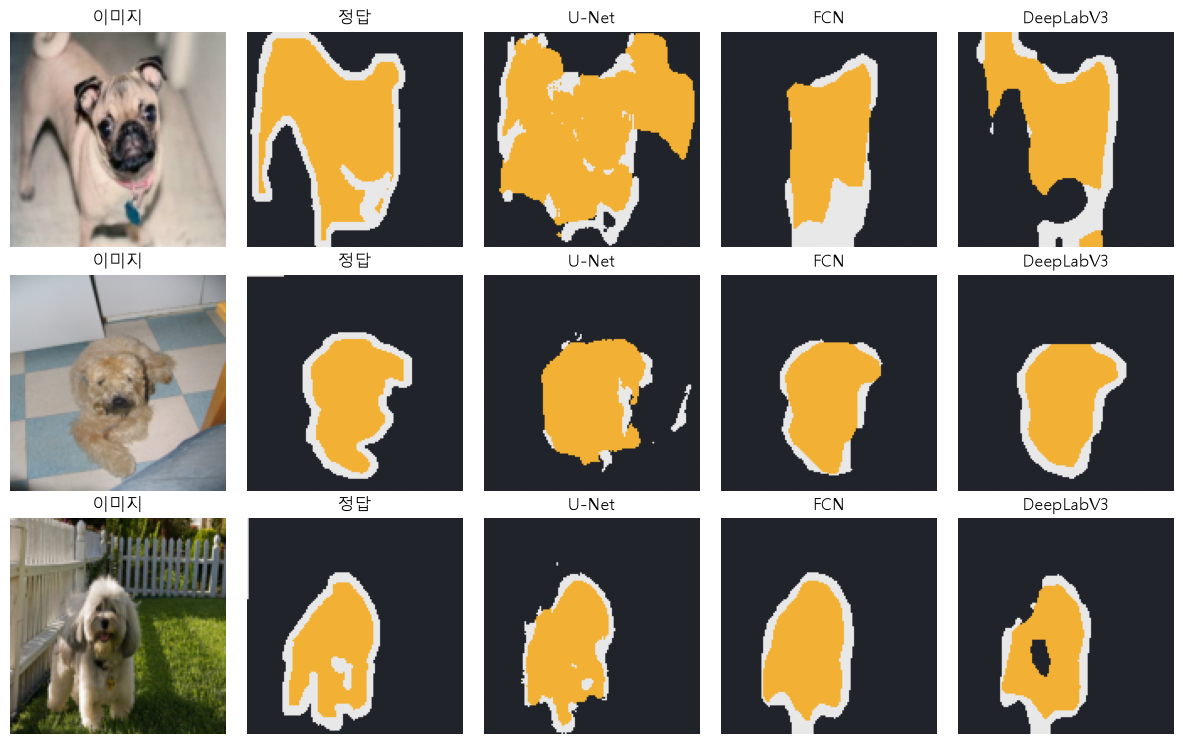

학습 시간 배수: {'U-Net': 1.0, 'FCN': 5.2, 'DeepLabV3': 6.1}


In [15]:
# [보강] 검증 3장: 이미지 · 정답 · 세 모델 예측
show = [0, 1, 2]                                                   # 검증 앞 3장
fig, ax = plt.subplots(len(show), 5, figsize=(12, 7.5))            # 3행 5열
for r, i in enumerate(show):                                       # 한 줄 = 한 장
    panels = [(X_val[i].permute(1, 2, 0), None, "이미지"),         # (그림, 색 규칙, 제목)
              (Y_val[i], CMAP, "정답")]
    for name, res in results.items():                              # 세 모델 예측
        panels.append((res["pred"][i], CMAP, name.split(" ")[0]))  # 모델 이름 첫 단어
    for c, (im, cmap, title) in enumerate(panels):                 # 다섯 칸
        if cmap is None:                                           # 사진이면
            ax[r, c].imshow(im)                                    # 원래 색 그대로
        else:
            ax[r, c].imshow(im, cmap=cmap, vmin=0, vmax=2)         # 번호별 고정 색
        ax[r, c].set_title(title)                                  # 칸 제목
        ax[r, c].axis("off")                                       # 눈금 숨김
plt.tight_layout()                                                 # 간격 정리
plt.show()                                                         # 그림 표시


# 학습 시간 비교 (U-Net 대비 몇 배)
base = results["U-Net (처음부터)"]["sec"]            # U-Net 시간 = 기준
ratio = {k.split(" ")[0]: round(v["sec"] / base, 1)  # 몇 배 걸렸나
         for k, v in results.items()}                # 모델 이름 첫 단어: 배수
print("학습 시간 배수:", ratio)                      # 모델별 배수

**결과** · 예측 정답은 아님 — 학습 시간은 U-Net의 약 3 ~ 4배

- GPU는 큰 행렬을 한 번에 계산하고, 128×128 작은 입력 · 데이터 준비 시간이 함께 들어감 (시간은 실행마다 조금씩 다름)
- `U-Net (처음부터)     | 픽셀 정확도 0.7726 | mIoU 0.5131 | mDice 0.6442` — 처음부터 5 epoch
- `| IoU [0.7529, 0.5849, 0.2015] | 파라미터 0.48M` — U-Net 경계 IoU 0.20
- `FCN (미세조정)       | 픽셀 정확도 0.8987 | mIoU 0.7143 | mDice 0.8135` — 가장 높은 mIoU
- `| IoU [0.8996, 0.8264, 0.4168] | 파라미터 32.95M` — 경계 IoU 0.42 → U-Net의 2배
- `DeepLabV3 (미세조정) | 픽셀 정확도 0.8977 | mIoU 0.7118 | mDice 0.8107` — FCN과 거의 같음 (차이 0.0025)
- `| IoU [0.9065, 0.821, 0.408] | 파라미터 39.63M` — 배경은 가장 잘, 경계는 FCN과 비슷

**실행 환경** · GPU(RTX 3060) 값, 같은 seed로 두 번 실행해 지표가 같음을 확인

- 학습 시간 초 · 배수는 컴퓨터 상태에 따라 달라짐

**세 모델 비교**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">모델</th>
<th style="text-align: left;">mIoU</th>
<th style="text-align: left;">mDice</th>
<th style="text-align: left;">경계 IoU</th>
<th style="text-align: left;">파라미터</th>
<th style="text-align: left;">학습 시간 (이 실행)</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">U-Net (처음부터)</td>
<td style="text-align: left;">0.5131</td>
<td style="text-align: left;">0.6442</td>
<td style="text-align: left;">0.2015</td>
<td style="text-align: left;">0.48M</td>
<td style="text-align: left;">기준 1배</td>
</tr>
<tr>
<td style="text-align: left;">FCN (미세조정)</td>
<td style="text-align: left;">0.7143</td>
<td style="text-align: left;">0.8135</td>
<td style="text-align: left;">0.4168</td>
<td style="text-align: left;">32.95M</td>
<td style="text-align: left;">약 3배</td>
</tr>
<tr>
<td style="text-align: left;">DeepLabV3 (미세조정)</td>
<td style="text-align: left;">0.7118</td>
<td style="text-align: left;">0.8107</td>
<td style="text-align: left;">0.4080</td>
<td style="text-align: left;">39.63M</td>
<td style="text-align: left;">약 3.5배</td>
</tr>
</tbody>
</table>

**그림 읽는 법**

- U-Net은 동물 몸통은 잡지만 경계(흰색)가 끊기고 배경에 얼룩이 생김
- 사전학습 두 모델은 동물 윤곽을 따라 경계 띠를 그림
- FCN과 DeepLabV3의 차이는 이 조건(128×128 · 5 epoch)에서는 거의 없음
  - DeepLabV3의 ASPP(여러 크기 문맥)는 큰 입력 · 크기가 다양한 물체에서 차이가 커짐

> ⚠️ **주의**
>
> - 5 epoch · 1회 실험의 FCN vs DeepLabV3 차이(0.0025)는 seed만 바꿔도 뒤집힐 수 있는 크기
> - \"비슷하다\"까지만 결론, 순위를 정하려면 여러 seed 평균

> ✅ **한 줄 정리** · 실제 사진 분할은 사전학습 모델의 분류기만 바꿔 미세조정하면 같은 조건에서 처음부터 학습한 U-Net보다 mIoU가 0.2 높고, 대신 모델이 크고 학습이 몇 배 느리다.

**딥러닝 코드에서는**

- 이 셀의 `setups`에 모델을 추가하는 방식으로 후보를 같은 조건에서 비교
- 가장 좋은 모델만 epoch를 늘려 다시 학습하고 `torch.save(model.state_dict(), "best.pt")`
- `.pt`는 GitHub에 올리지 않음

### 5장 더 알아보기 · 방법별 차이

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">U-Net 처음부터</td>
<td style="text-align: left;">작고 빠름, 데이터 · epoch가 많이 필요</td>
<td style="text-align: left;">사전학습 모델이 없는 영상 (의료 · 위성 다채널), 기기에 올릴 작은 모델</td>
</tr>
<tr>
<td style="text-align: left;">FCN 미세조정</td>
<td style="text-align: left;">가장 단순한 구조, 이 실험에서 DeepLabV3와 비슷</td>
<td style="text-align: left;">빠른 기준선 · 비교 대상</td>
</tr>
<tr>
<td style="text-align: left;">DeepLabV3 미세조정</td>
<td style="text-align: left;">ASPP로 여러 크기 문맥, 가장 큼</td>
<td style="text-align: left;">일반 사진 · 다양한 크기 물체 (기본 선택)</td>
</tr>
<tr>
<td style="text-align: left;">같은 조건 비교</td>
<td style="text-align: left;">데이터 · 증강 · 손실 · epoch 고정, lr만 학습 방식에 맞춤</td>
<td style="text-align: left;">모델 선택 보고 (조건이 다르면 비교 무의미)</td>
</tr>
</tbody>
</table>

---
## 그래서 오늘 무엇을 배웠는가?

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">학습 목표</th>
<th style="text-align: left;">할 수 있게 된 것</th>
<th style="text-align: left;">확인 위치</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">1. 마스크 준비</td>
<td style="text-align: left;">trimap 1 · 2 · 3 → <code>LUT</code>로 0 · 1 · 2, 마스크는 nearest (bilinear면 가짜 동물 픽셀 256개)</td>
<td style="text-align: left;">1-1 · 1-2</td>
</tr>
<tr>
<td style="text-align: left;">2. 함께 증강</td>
<td style="text-align: left;">함께 넣으면 일치율 0.9462, 따로 넣으면 0.4555</td>
<td style="text-align: left;">1-3</td>
</tr>
<tr>
<td style="text-align: left;">3. 불균형 대응</td>
<td style="text-align: left;">경계 IoU 일반 CE 0.1763 → 가중 CE 0.2921 · Dice 0.2894</td>
<td style="text-align: left;">2-1 · 2-2</td>
</tr>
<tr>
<td style="text-align: left;">4. 사전학습 미세조정</td>
<td style="text-align: left;">같은 DeepLabV3 2 epoch: 처음부터 mIoU 0.3964 vs 미세조정 0.6942</td>
<td style="text-align: left;">3-1 · 3-2</td>
</tr>
<tr>
<td style="text-align: left;">5. 출력 형식</td>
<td style="text-align: left;">인스턴스 3개(중복 포함) → 파놉틱 2개, 의미 분할은 개체 수 없음</td>
<td style="text-align: left;">4-1 · 4-2</td>
</tr>
</tbody>
</table>

### 주제별 한 줄 · 반드시 기억할 것

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: center;">등급</th>
<th style="text-align: left;">주제</th>
<th style="text-align: left;">반드시 기억할 것</th>
<th style="text-align: left;">코드에서</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: center;"><code>A</code></td>
<td style="text-align: left;">마스크 번호</td>
<td style="text-align: left;">값 종류 먼저 확인, 0부터 연속으로</td>
<td style="text-align: left;"><code>LUT[mask]</code></td>
</tr>
<tr>
<td style="text-align: center;"><code>A</code></td>
<td style="text-align: left;">크기 조정</td>
<td style="text-align: left;">이미지 bilinear · 마스크 nearest</td>
<td style="text-align: left;"><code>Image.NEAREST</code></td>
</tr>
<tr>
<td style="text-align: center;"><code>A</code></td>
<td style="text-align: left;">함께 증강</td>
<td style="text-align: left;">같은 난수로 이미지 · 마스크 동시에</td>
<td style="text-align: left;"><code>tf(tv_tensors.Image(x), tv_tensors.Mask(m))</code></td>
</tr>
<tr>
<td style="text-align: center;"><code>A</code></td>
<td style="text-align: left;">불균형</td>
<td style="text-align: left;">1 / 비율 가중치, 지표는 mIoU</td>
<td style="text-align: left;"><code>F.cross_entropy(weight=w)</code></td>
</tr>
<tr>
<td style="text-align: center;"><code>A</code></td>
<td style="text-align: left;">분류기 교체</td>
<td style="text-align: left;">마지막 1×1 합성곱만 내 클래스 수로</td>
<td style="text-align: left;"><code>model.classifier[4] = nn.Conv2d(256, 3, 1)</code></td>
</tr>
<tr>
<td style="text-align: center;"><code>A</code></td>
<td style="text-align: left;">미세조정</td>
<td style="text-align: left;">사전학습 정규화 + 작은 lr</td>
<td style="text-align: left;"><code>v2.Normalize(MEAN, STD)</code> · <code>lr=1e-4</code></td>
</tr>
<tr>
<td style="text-align: center;"><code>A</code></td>
<td style="text-align: left;">인스턴스 출력</td>
<td style="text-align: left;">상자 · 클래스 · 점수 · 확률 마스크, 겹칠 수 있음</td>
<td style="text-align: left;"><code>out["masks"][keep, 0] &gt; 0.5</code></td>
</tr>
<tr>
<td style="text-align: center;"><code>B</code></td>
<td style="text-align: left;">손실 비교</td>
<td style="text-align: left;">손실 하나만 바꿔 같은 조건</td>
<td style="text-align: left;"><code>train(UNet, loss_fn, ...)</code></td>
</tr>
<tr>
<td style="text-align: center;"><code>B</code></td>
<td style="text-align: left;">파놉틱</td>
<td style="text-align: left;">모든 픽셀에 (클래스, ID) 하나, 중복 정리</td>
<td style="text-align: left;">점수 순서 · 절반 규칙</td>
</tr>
<tr>
<td style="text-align: center;"><code>B</code></td>
<td style="text-align: left;">GPU 재현</td>
<td style="text-align: left;">cudnn 설정 + 결정적 알고리즘</td>
<td style="text-align: left;"><code>torch.use_deterministic_algorithms(True)</code></td>
</tr>
</tbody>
</table>

---
## 기억 확인 문제

위 내용을 **보지 않고** 답한 뒤, ✅ 한 줄 정리와 비교해 ○ (정확) · △ (일부) · × (모름)를 표시. △ · ×인 섹션만 다시 보기.

### 1. 질문에 답하기

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">섹션</th>
<th style="text-align: left;">🎯 질문</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">1-1</td>
<td style="text-align: left;">Oxford Pet의 trimap 값은 무엇이고, 학습 번호로 어떻게 바꾸는가?</td>
</tr>
<tr>
<td style="text-align: left;">1-2</td>
<td style="text-align: left;">마스크를 bilinear로 줄이면 어떤 문제가 생기는가?</td>
</tr>
<tr>
<td style="text-align: left;">1-3</td>
<td style="text-align: left;">위치를 바꾸는 증강에서 이미지와 마스크를 어긋나지 않게 하는 법은?</td>
</tr>
<tr>
<td style="text-align: left;">2-1</td>
<td style="text-align: left;">가중 CE의 가중치는 어떻게 정하며, 무엇을 바꾸는가?</td>
</tr>
<tr>
<td style="text-align: left;">2-2</td>
<td style="text-align: left;">일반 CE · 가중 CE · Dice 중 경계 IoU가 가장 낮았던 것은?</td>
</tr>
<tr>
<td style="text-align: left;">3-1</td>
<td style="text-align: left;">사전학습 DeepLabV3를 3클래스에 맞추려면 어디를 바꾸는가?</td>
</tr>
<tr>
<td style="text-align: left;">3-2</td>
<td style="text-align: left;">처음부터 학습과 사전학습 미세조정의 차이는 같은 조건에서 얼마였나?</td>
</tr>
<tr>
<td style="text-align: left;">4-1</td>
<td style="text-align: left;">Mask R-CNN의 출력 4가지와 마스크 모양은?</td>
</tr>
<tr>
<td style="text-align: left;">4-2</td>
<td style="text-align: left;">의미 · 인스턴스 · 파놉틱 출력의 차이는?</td>
</tr>
<tr>
<td style="text-align: left;">5</td>
<td style="text-align: left;">U-Net · FCN · DeepLabV3 비교의 결론은?</td>
</tr>
</tbody>
</table>

#### 내 답 · 이 셀을 더블클릭해서 작성

**1-1** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**1-2** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**1-3** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**2-1** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**2-2** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**3-1** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**3-2** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**4-1** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**4-2** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**5** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

### 2. 코드로 답하기

아래 빈 셀에 직접 작성 후 실행.

1. trimap `np.array([[1, 2], [3, 2]])`를 `LUT = np.array([0, 1, 0, 2])`로 바꾼 결과를 리스트로 출력
2. 마스크 `torch.tensor([[[0., 2.]]])`(모양 (1, 1, 2))를 `nearest`로 너비 4까지 키운 값을 출력
3. 픽셀 수 `[600, 300, 100]`의 클래스 가중치(1 / 비율을 평균 1로)를 소수 넷째 자리로 출력
4. 21클래스 머리 `nn.Conv2d(256, 21, 1)`을 3클래스로 바꾼 층의 출력 채널 수를 출력

In [16]:
# 코드 문제 직접 작성

### 3. 변형 문제 · 조건을 바꿔 다시 풀기

1. 경계(3)를 동물로 합쳐 **2클래스**(배경 · 동물)로 학습하려면 `LUT`를 어떻게 바꿀까?
2. 픽셀 수가 `[700, 200, 100]`이면 2-1 방식의 클래스 가중치(평균 1)는? 손계산 → 코드
3. 사전학습 FCN을 **5클래스**로 쓰려면 어느 층을 무엇으로 바꾸고, 출력 모양은?

In [17]:
# 변형 문제 직접 작성

### 4. 모범 답안 · 1 ~ 3을 다 푼 뒤에 보기

#### 질문 답

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">섹션</th>
<th style="text-align: left;">답</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">1-1</td>
<td style="text-align: left;">1 동물 · 2 배경 · 3 경계 → <code>LUT = [0, 1, 0, 2]</code>로 0 배경 · 1 동물 · 2 경계</td>
</tr>
<tr>
<td style="text-align: left;">1-2</td>
<td style="text-align: left;">번호 사이 값(1.7 등)이 생기고 반올림해도 0과 2 사이가 1(동물)이 됨 → 마스크는 nearest</td>
</tr>
<tr>
<td style="text-align: left;">1-3</td>
<td style="text-align: left;"><code>v2</code> 변환에 <code>tv_tensors.Image</code> · <code>tv_tensors.Mask</code>를 함께 넣어 같은 난수로 변환</td>
</tr>
<tr>
<td style="text-align: left;">2-1</td>
<td style="text-align: left;">1 / 픽셀 비율을 평균 1로 맞춤, 드문 클래스 픽셀의 손실 비중을 키움</td>
</tr>
<tr>
<td style="text-align: left;">2-2</td>
<td style="text-align: left;">일반 CE (0.1763), 가중 CE 0.2921 · Dice 0.2894</td>
</tr>
<tr>
<td style="text-align: left;">3-1</td>
<td style="text-align: left;"><code>classifier[4]</code>의 1×1 합성곱 21 → 3, <code>aux_classifier = None</code></td>
</tr>
<tr>
<td style="text-align: left;">3-2</td>
<td style="text-align: left;">2 epoch에 mIoU 0.3964 vs 0.6942</td>
</tr>
<tr>
<td style="text-align: left;">4-1</td>
<td style="text-align: left;"><code>boxes</code> · <code>labels</code> · <code>scores</code> · <code>masks</code>(N, 1, H, W 확률)</td>
</tr>
<tr>
<td style="text-align: left;">4-2</td>
<td style="text-align: left;">의미 = 클래스 지도, 인스턴스 = 겹칠 수 있는 개체 목록(배경 없음), 파놉틱 = 픽셀마다 (클래스, ID)</td>
</tr>
<tr>
<td style="text-align: left;">5</td>
<td style="text-align: left;">사전학습 두 모델이 U-Net보다 mIoU 약 0.2 높고, 학습은 약 3 ~ 4배 느림. FCN과 DeepLabV3는 이 조건에서 비슷</td>
</tr>
</tbody>
</table>

#### 코드 문제 답

```python
# 1. LUT 표로 번호 바꾸기
LUT = np.array([0, 1, 0, 2])
print(LUT[np.array([[1, 2], [3, 2]])].tolist())  # [[1, 0], [2, 0]]

# 2. 마스크는 nearest로 키우기 (번호 그대로)
m = torch.tensor([[[0., 2.]]])
up = F.interpolate(m, size=4, mode="nearest")
print(up.tolist())  # [[[0.0, 0.0, 2.0, 2.0]]]

# 3. 클래스 가중치 = 1 / 비율 → 평균 1
counts = torch.tensor([600., 300., 100.])
w = 1 / (counts / counts.sum())
print([round(v, 4) for v in (w / w.mean()).tolist()])  # [0.3333, 0.6667, 2.0]

# 4. 분류기 교체 후 출력 채널
head = nn.Conv2d(256, 3, kernel_size=1)
print(head.out_channels)  # 3
```

#### 변형 문제 답

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">문제</th>
<th style="text-align: left;">답</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">1</td>
<td style="text-align: left;"><code>LUT = np.array([0, 1, 0, 1])</code> — 2 배경 → 0, 1 동물 · 3 경계 → 1 (모델 출력 채널도 2)</td>
</tr>
<tr>
<td style="text-align: left;">2</td>
<td style="text-align: left;">비율 0.7 · 0.2 · 0.1 → 1 ÷ 비율 1.4286 · 5 · 10 → 평균 5.4762로 나눠 <code>[0.2609, 0.913, 1.8261]</code></td>
</tr>
<tr>
<td style="text-align: left;">3</td>
<td style="text-align: left;"><code>fcn.classifier[4] = nn.Conv2d(512, 5, kernel_size=1)</code> → <code>out</code> 모양 <code>(N, 5, H, W)</code></td>
</tr>
</tbody>
</table>

---
## 오답 노트

틀린 문제는 정답을 베끼지 말고 **원인**을 적음. 다음 복습 때 이 표의 "재발 방지 질문"부터 스스로에게 물어보기.

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">틀린 내용</th>
<th style="text-align: left;">틀린 이유</th>
<th style="text-align: left;">올바른 원칙</th>
<th style="text-align: left;">재발 방지 질문</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">(예) 마스크를 이미지와 같은 <code>Resize</code>로 줄임</td>
<td style="text-align: left;">둘 다 그림이라고 생각</td>
<td style="text-align: left;">마스크는 번호표 → nearest</td>
<td style="text-align: left;">마스크 보간이 nearest인가?</td>
</tr>
<tr>
<td style="text-align: left;"></td>
<td style="text-align: left;"></td>
<td style="text-align: left;"></td>
<td style="text-align: left;"></td>
</tr>
<tr>
<td style="text-align: left;"></td>
<td style="text-align: left;"></td>
<td style="text-align: left;"></td>
<td style="text-align: left;"></td>
</tr>
</tbody>
</table>

---
## 면접 30초 답변

**Q1. 분할 데이터에 증강을 적용할 때 주의할 점은 무엇인가요?**
> - 자르기
> - 뒤집기처럼 위치를 바꾸는 증강은 이미지와 마스크에 같은 난수로 함께 적용해야 합니다.
> - 따로 적용하면 제 실습에서 이미지와 마스크의 일치율이 0.46까지 떨어졌습니다.
> - 또 마스크는 클래스 번호라서 크기를 바꿀 때 bilinear 대신 nearest를 써야 없는 번호가 생기지 않습니다.
> - torchvision v2에 `tv_tensors.Mask`로 넣으면 이 두 가지를 자동으로 처리합니다.

**Q2. 분할에서 클래스 불균형은 어떻게 다루나요?**
> - 픽셀 비율이 낮은 클래스는 일반 교차 엔트로피에서 비중이 작아 놓치기 쉽습니다.
> - 클래스별 비율의 역수로 가중치를 준 가중 교차 엔트로피나, 클래스마다 겹침 비율을 보는 Dice 손실을 씁니다.
> - Oxford Pet에서 경계 클래스 IoU가 일반 CE 0.18에서 가중 CE 0.29로 올랐습니다.
> - 평가도 픽셀 정확도가 아니라 mIoU로 봅니다.

**Q3. 사전학습 분할 모델은 어떻게 내 데이터에 맞추나요?**
> - torchvision의 DeepLabV3나 FCN은 마지막 1×1 합성곱이 사전학습 클래스 수만큼의 채널을 내므로, 그 층만 내 클래스 수로 바꾸고 작은 학습률로 전체를 미세조정합니다.
> - 입력은 사전학습 때와 같은 정규화를 해야 합니다.
> - 같은 구조를 처음부터 학습했을 때보다 2 epoch 만에 mIoU가 0.40에서 0.69로 높았습니다.

**Q4. Semantic, Instance, Panoptic Segmentation의 출력 차이는요?**
> - Semantic은 픽셀마다 클래스를 붙인 지도 한 장이라 같은 클래스 개체를 구분하지 못합니다.
> - Instance는 개체마다 클래스 · 점수
> - 마스크를 낸 목록이라 마스크끼리 겹칠 수 있고 배경은 출력하지 않습니다.
> - Panoptic은 모든 픽셀에 클래스와 개체 ID를 정확히 하나씩 붙이며, 실습에서는 Mask R-CNN의 중복 마스크를 점수 순서로 합쳐 정리했습니다.

---
## 최종 요약표

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">함수·문법</th>
<th style="text-align: left;">소속</th>
<th style="text-align: left;">역할</th>
<th style="text-align: left;">코드에서 사용한 위치</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;"><code>torchvision.datasets.OxfordIIITPet(target_types="segmentation")</code></td>
<td style="text-align: left;">torchvision</td>
<td style="text-align: left;">사진 + trimap 마스크 데이터셋</td>
<td style="text-align: left;">0-2 <code>pet = torchvision.datasets.OxfordIIITPet(</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>LUT[mask]</code></td>
<td style="text-align: left;">numpy</td>
<td style="text-align: left;">값 → 새 번호 표 찾기 (반복문 없음)</td>
<td style="text-align: left;">1-1 <code>LUT = np.array([0, 1, 0, 2])</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>Image.resize(size, Image.BILINEAR · NEAREST)</code></td>
<td style="text-align: left;">PIL</td>
<td style="text-align: left;">이미지 · 마스크 크기 조정</td>
<td style="text-align: left;">1-2 <code>img.resize((SIZE, SIZE), Image.BILINEAR)</code> · <code>tri.resize((SIZE, SIZE), Image.NEAREST)</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>v2.RandomResizedCrop</code> · <code>v2.RandomHorizontalFlip</code></td>
<td style="text-align: left;">torchvision.transforms.v2</td>
<td style="text-align: left;">위치를 바꾸는 증강</td>
<td style="text-align: left;">1-3 <code>v2.RandomResizedCrop(SIZE, scale=(0.5, 1.0), antia…</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>v2.ToDtype(scale=True)</code> · <code>v2.Normalize</code></td>
<td style="text-align: left;">torchvision.transforms.v2</td>
<td style="text-align: left;">이미지만 실수 · 정규화</td>
<td style="text-align: left;">1-3 <code>train_tf = v2.Compose([geo_tf, v2.ToDtype(torch.fl…</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>tv_tensors.Image</code> · <code>tv_tensors.Mask</code></td>
<td style="text-align: left;">torchvision</td>
<td style="text-align: left;">함께 증강할 때 종류 표시</td>
<td style="text-align: left;">1-3 <code>probe = tv_tensors.Image((Y_train[0] * 100).to(tor…</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>torch.bincount(mask.flatten())</code></td>
<td style="text-align: left;">torch</td>
<td style="text-align: left;">클래스별 픽셀 수</td>
<td style="text-align: left;">2-1 <code>counts = torch.bincount(Y_train.flatten(), minleng…</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>F.cross_entropy(weight=)</code></td>
<td style="text-align: left;">torch.nn.functional</td>
<td style="text-align: left;">가중 CE</td>
<td style="text-align: left;">2-1 <code>pixel_ce(all_bg, target, weight)</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>permute(0, 2, 3, 1).reshape(-1, C)</code></td>
<td style="text-align: left;">torch.Tensor</td>
<td style="text-align: left;">픽셀을 펼쳐 (N·H·W, C)</td>
<td style="text-align: left;">2-1 <code>return F.cross_entropy(logits.permute(0, 2, 3, 1).…</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>torch.use_deterministic_algorithms(True)</code></td>
<td style="text-align: left;">torch</td>
<td style="text-align: left;">GPU 결과 재현 (결정적 구현이 없으면 에러로 알려 줌)</td>
<td style="text-align: left;">0-1 <code>torch.use_deterministic_algorithms(True)</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>train()</code> · <code>evaluate()</code></td>
<td style="text-align: left;">보강 함수</td>
<td style="text-align: left;">같은 조건 학습 · 혼동 행렬 평가</td>
<td style="text-align: left;">2-2 <code>train(UNet, fn, epochs=4, lr=1e-3)</code> · <code>evaluate(model)</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>segmentation.deeplabv3_resnet50(weights=)</code></td>
<td style="text-align: left;">torchvision.models</td>
<td style="text-align: left;">ResNet-50 + ASPP 분할 모델</td>
<td style="text-align: left;">3-1 <code>dl = segmentation.deeplabv3_resnet50(weights=DL_W)…</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>segmentation.fcn_resnet50(weights=)</code></td>
<td style="text-align: left;">torchvision.models</td>
<td style="text-align: left;">ResNet-50 + FCN 머리</td>
<td style="text-align: left;">3-1 <code>fcn = segmentation.fcn_resnet50(weights=FCN_W)</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>Weights.DEFAULT</code> · <code>meta["categories"]</code></td>
<td style="text-align: left;">torchvision.models</td>
<td style="text-align: left;">사전학습 가중치 · 클래스 이름</td>
<td style="text-align: left;">3-1 <code>DL_W = segmentation.DeepLabV3_ResNet50_Weights.DEF…</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>model.classifier[4] = nn.Conv2d(c, 3, 1)</code></td>
<td style="text-align: left;">torch.nn</td>
<td style="text-align: left;">분류기 교체</td>
<td style="text-align: left;">3-1 <code>dl.classifier[4] = nn.Conv2d(256, 3, kernel_size=1)</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>model.aux_classifier = None</code> · <code>model(x)["out"]</code></td>
<td style="text-align: left;">torchvision.models</td>
<td style="text-align: left;">보조 출력 끄기 · 분할 점수 꺼내기</td>
<td style="text-align: left;">3-1 <code>fcn.aux_classifier = None</code> · 2-2 <code>out["out"] if isinstance(out, dict)</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>detection.maskrcnn_resnet50_fpn(weights=)</code></td>
<td style="text-align: left;">torchvision.models</td>
<td style="text-align: left;">인스턴스 분할 모델</td>
<td style="text-align: left;">4-1 <code>mrcnn = detection.maskrcnn_resnet50_fpn(weights=MR…</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>model([img])[0]</code></td>
<td style="text-align: left;">torchvision.models</td>
<td style="text-align: left;">이미지 리스트 → 이미지마다 dict</td>
<td style="text-align: left;">4-1 <code>mrcnn([MR_W.transforms()(scene).to(device)])[0]</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>boxes</code> · <code>labels</code> · <code>scores</code> · <code>masks</code></td>
<td style="text-align: left;">Mask R-CNN 출력</td>
<td style="text-align: left;">상자 · 클래스 · 점수 · (N, 1, H, W) 확률 마스크</td>
<td style="text-align: left;">4-1 <code>det["boxes"][keep]</code> · <code>det["scores"] &gt; 0.5</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>masks[scores &gt; 0.5, 0] &gt; 0.5</code></td>
<td style="text-align: left;">torch.Tensor</td>
<td style="text-align: left;">점수 · 마스크 기준값으로 자르기</td>
<td style="text-align: left;">4-1 <code>det["masks"][keep, 0] &gt; 0.5</code></td>
</tr>
<tr>
<td style="text-align: left;">파놉틱 합치기 (점수 순서 · 절반 규칙)</td>
<td style="text-align: left;">보강 코드 (위클리 10 단순화)</td>
<td style="text-align: left;">모든 픽셀에 (클래스, ID) 하나</td>
<td style="text-align: left;">4-2 <code>if free.sum() &lt; 0.5 * m.sum():</code></td>
</tr>
</tbody>
</table>

### 할 것 · 하지 말 것

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">✅ 할 것</th>
<th style="text-align: left;">⚠️ 하지 말 것</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">마스크 값 종류부터 <code>np.unique</code></td>
<td style="text-align: left;">trimap 1 · 2 · 3 그대로 학습</td>
</tr>
<tr>
<td style="text-align: left;">마스크는 nearest</td>
<td style="text-align: left;">마스크에 bilinear · <code>/ 255</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>v2</code> + <code>tv_tensors.Mask</code>로 함께 증강</td>
<td style="text-align: left;">이미지 · 마스크 따로 증강</td>
</tr>
<tr>
<td style="text-align: left;">가중 CE · Dice로 드문 클래스 보정</td>
<td style="text-align: left;">픽셀 정확도만 보고 판단</td>
</tr>
<tr>
<td style="text-align: left;">사전학습 정규화 · 작은 lr</td>
<td style="text-align: left;">정규화 없이 사전학습 모델에 입력</td>
</tr>
<tr>
<td style="text-align: left;">인스턴스 결과는 점수 · 중복 정리</td>
<td style="text-align: left;">마스크 개수 = 개체 수라고 바로 세기</td>
</tr>
<tr>
<td style="text-align: left;"><code>data/</code> · <code>.pt</code>는 <code>.gitignore</code></td>
<td style="text-align: left;">내려받은 데이터 · 가중치를 저장소에 올리기</td>
</tr>
</tbody>
</table>

### 헷갈리는 짝 한눈에 보기

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">짝</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">결론</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">이미지 bilinear vs 마스크 nearest</td>
<td style="text-align: left;">가중 평균 vs 값 복사</td>
<td style="text-align: left;">마스크는 항상 nearest</td>
</tr>
<tr>
<td style="text-align: left;">함께 증강 vs 따로 증강</td>
<td style="text-align: left;">같은 난수 1번 vs 난수 2번</td>
<td style="text-align: left;"><code>v2</code> + <code>tv_tensors.Mask</code>로 함께</td>
</tr>
<tr>
<td style="text-align: left;">trimap 그대로 vs <code>LUT</code> 변환</td>
<td style="text-align: left;">1 · 2 · 3 vs 0 · 1 · 2</td>
<td style="text-align: left;">번호는 0부터 연속으로</td>
</tr>
<tr>
<td style="text-align: left;">일반 CE vs 가중 CE vs Dice</td>
<td style="text-align: left;">픽셀 비중 vs 클래스 가중 vs 클래스 겹침</td>
<td style="text-align: left;">불균형이면 가중 CE · Dice</td>
</tr>
<tr>
<td style="text-align: left;"><code>F.cross_entropy</code> vs <code>pixel_ce</code></td>
<td style="text-align: left;">모양 그대로 vs 펼쳐서 (같은 값)</td>
<td style="text-align: left;">GPU 재현이 필요하면 펼쳐서</td>
</tr>
<tr>
<td style="text-align: left;">처음부터 vs 사전학습 미세조정</td>
<td style="text-align: left;">무작위 시작 vs 학습된 특징에서 시작</td>
<td style="text-align: left;">일반 사진은 미세조정</td>
</tr>
<tr>
<td style="text-align: left;">U-Net vs FCN vs DeepLabV3</td>
<td style="text-align: left;">skip 이어 붙이기 vs 한 번에 업샘플 vs ASPP 문맥</td>
<td style="text-align: left;">사진은 DeepLabV3, 적은 데이터 · 경계는 U-Net</td>
</tr>
<tr>
<td style="text-align: left;">탐지 박스 vs 인스턴스 마스크</td>
<td style="text-align: left;">직사각형 vs 픽셀 모양</td>
<td style="text-align: left;">모양 · 넓이가 필요하면 마스크</td>
</tr>
<tr>
<td style="text-align: left;">의미 vs 인스턴스 vs 파놉틱</td>
<td style="text-align: left;">클래스 지도 vs 개체 목록 vs (클래스, ID) 지도</td>
<td style="text-align: left;">영역 · 개체 · 둘 다</td>
</tr>
<tr>
<td style="text-align: left;"><code>weights=</code> vs <code>weights_backbone=</code></td>
<td style="text-align: left;">모델 전체 vs 백본만 사전학습</td>
<td style="text-align: left;">분할 사전학습은 <code>weights=</code></td>
</tr>
</tbody>
</table>

---
## 다음 복습일

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">언제</th>
<th style="text-align: left;">할 일</th>
<th style="text-align: left;">걸리는 시간</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">내일</td>
<td style="text-align: left;">기억 확인 문제 1을 자료 없이 다시 답하고 오답 노트 갱신</td>
<td style="text-align: left;">15분</td>
</tr>
<tr>
<td style="text-align: left;">3일 뒤</td>
<td style="text-align: left;">변형 문제 3개를 새로 풀기 · 1-3 함께 증강 코드를 가리고 다시 쓰기</td>
<td style="text-align: left;">20분</td>
</tr>
<tr>
<td style="text-align: left;">7일 뒤</td>
<td style="text-align: left;">다른 분할 데이터(또는 Pet 다른 1000장)로 5장 비교를 다시 돌려 숫자 비교</td>
<td style="text-align: left;">40분</td>
</tr>
<tr>
<td style="text-align: left;">14일 뒤</td>
<td style="text-align: left;">오답 노트에 남은 문제만 · 프로젝트 전에 1 · 3장 ✅ 줄만 읽기</td>
<td style="text-align: left;">15분</td>
</tr>
</tbody>
</table>

---
## 부록

### 이 노트북을 만든 방법

- 세그멘테이션-1(도형 데이터 · U-Net · mIoU · Dice)에 이어 실제 사진 데이터셋으로 넘어감
- 데이터셋: **Oxford-IIIT Pet**(배경 · 동물 · 경계 마스크)
- 구성: **4개 대단원 · 9개 섹션** + 마지막 **종합 실습**(직접 만든 U-Net vs 사전학습 FCN · DeepLabV3 미세조정)
- 개념: 위클리 페이퍼 10(Instance · Panoptic · 객체 추적) · Segmentation PDF의 Instance · Mask R-CNN 부분

**수업 실행 코드가 없는 단원이라 코드는 모두 보강**

- 개념은 위클리 10
- PDF를 따르고, 코드 셀 · 실험
- 수치는 이 정리본에서 새로 작성 (섹션 제목의 <sub>개념 … · 코드 보강</sub> 표시, 코드 첫 주석의 `[보강]`)

### 읽는 법

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">표시</th>
<th style="text-align: left;">의미</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;"><code>A</code> · <code>B</code></td>
<td style="text-align: left;"><strong>A</strong> 실전 분할 코드에 바로 나오는 필수 · <strong>B</strong> 알아두면 되는 것</td>
</tr>
<tr>
<td style="text-align: left;">🎯</td>
<td style="text-align: left;">이번 섹션에서 답해야 할 질문</td>
</tr>
<tr>
<td style="text-align: left;">💡</td>
<td style="text-align: left;">쉬운 설명 · 비유</td>
</tr>
<tr>
<td style="text-align: left;">⚠️</td>
<td style="text-align: left;">자주 하는 실수</td>
</tr>
<tr>
<td style="text-align: left;">✅</td>
<td style="text-align: left;">기억할 결론 = 🎯 질문의 답</td>
</tr>
<tr>
<td style="text-align: left;"><sub>개념 PDF · 위클리 · 코드 보강</sub></td>
<td style="text-align: left;">개념의 출처 (PDF 쪽 = 파일의 쪽 번호), 코드는 모두 보강</td>
</tr>
</tbody>
</table>

**섹션 구성** · 🎯 질문 → 💡 쉬운 설명 → 실행 흐름 → 먼저 예측 → 코드 → 예측 정답 · 결과 해설 → 차이 · 언제 쓰나 → ⚠️ 주의 → ✅ 한 줄 정리

**코드 주석** · 코드 위 = 이 단계에서 하는 일, 코드 옆 = 실행 흐름 · 문법 구조

### 원본 → 섹션 대응표

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">원본</th>
<th style="text-align: left;">내용</th>
<th style="text-align: left;">섹션</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">위클리 10</td>
<td style="text-align: left;">Semantic vs Instance vs Panoptic 출력 형식, Mask R-CNN · DeepLabV3 코드, 겹친 개체 실패 사례, 학습 손실(클래스 가중치 · Dice), PQ · 객체 추적</td>
<td style="text-align: left;">2-1 · 2-2 · 3-1 · 4-1 · 4-2</td>
</tr>
<tr>
<td style="text-align: left;">PDF 4쪽 · 44~51쪽</td>
<td style="text-align: left;">Semantic · Instance · Panoptic 정의, 출력 · 구조 · 학습 전략 비교</td>
<td style="text-align: left;">4-1 · 4-2</td>
</tr>
<tr>
<td style="text-align: left;">PDF 52~62쪽</td>
<td style="text-align: left;">Mask R-CNN (Faster R-CNN + 마스크 머리, RoIAlign, 다중 작업 손실)</td>
<td style="text-align: left;">4-1</td>
</tr>
<tr>
<td style="text-align: left;">PDF 11~15 · 46쪽</td>
<td style="text-align: left;">보간 방법 · U-Net 데이터 증강</td>
<td style="text-align: left;">1-2 · 1-3</td>
</tr>
<tr>
<td style="text-align: left;">위클리 9 Q2 보충</td>
<td style="text-align: left;">DeepLab(팽창 합성곱 · ASPP), FCN의 사전학습 가중치 재사용</td>
<td style="text-align: left;">3-1 · 3-2</td>
</tr>
<tr>
<td style="text-align: left;">위클리 10 객체 추적 (SORT · DeepSORT · ByteTrack)</td>
<td style="text-align: left;">영상 프레임 사이 ID 잇기</td>
<td style="text-align: left;">4-2 딥러닝 코드에서는 (한 줄 소개만)</td>
</tr>
<tr>
<td style="text-align: left;">미션 8</td>
<td style="text-align: left;">U-Net 축구 데이터</td>
<td style="text-align: left;">제외</td>
</tr>
</tbody>
</table>

### 세그멘테이션-1과 겹치는 내용 (여기서는 참조만)

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">내용</th>
<th style="text-align: left;">자세한 설명</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">U-Net 구조 · skip · 모양 추적</td>
<td style="text-align: left;">세그멘테이션-1 3-1 · 3-2 (여기서는 3단으로 늘린 것만 0장에 정의)</td>
</tr>
<tr>
<td style="text-align: left;">픽셀 정확도 · mIoU · Dice (<code>seg_metrics</code>) · Dice 손실</td>
<td style="text-align: left;">세그멘테이션-1 4-1 · 4-2</td>
</tr>
<tr>
<td style="text-align: left;">픽셀 CE · <code>ignore_index</code> · 업샘플링 · FCN 1×1 합성곱</td>
<td style="text-align: left;">세그멘테이션-1 2-1 ~ 2-3</td>
</tr>
<tr>
<td style="text-align: left;">상자 IoU · NMS</td>
<td style="text-align: left;">객체탐지-1</td>
</tr>
</tbody>
</table>

### 단원 연결 · 왜 이 순서로 배우는가

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: center;">순서</th>
<th style="text-align: left;">배우는 이유</th>
<th style="text-align: left;">대단원</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: center;">1</td>
<td style="text-align: left;">실제 데이터는 번호 규칙 · 크기가 제각각이라 정리부터</td>
<td style="text-align: left;">실제 데이터 준비</td>
</tr>
<tr>
<td style="text-align: center;">2</td>
<td style="text-align: left;">실제 마스크는 클래스 비율이 크게 다름</td>
<td style="text-align: left;">클래스 불균형</td>
</tr>
<tr>
<td style="text-align: center;">3</td>
<td style="text-align: left;">사진 데이터는 이미 학습된 모델에서 출발하면 빠르고 정확함</td>
<td style="text-align: left;">사전학습 분할 모델</td>
</tr>
<tr>
<td style="text-align: center;">4</td>
<td style="text-align: left;">영역이 아니라 개체 하나하나가 필요할 때가 있음</td>
<td style="text-align: left;">Instance · Panoptic</td>
</tr>
<tr>
<td style="text-align: center;">5</td>
<td style="text-align: left;">1~3을 합쳐 직접 만든 모델과 사전학습 모델을 같은 조건에서 비교</td>
<td style="text-align: left;">종합 실습</td>
</tr>
</tbody>
</table>

### 전체 코드

0 ~ 5장 코드를 섹션 순서대로 셀에 모음. **위에서부터 이 셀들만 실행해도 전체가 동작**함

- 데이터 준비 · 모든 학습 포함 (GPU에서 수 분)
- 그림은 각 섹션에서 보고 여기서는 닫음(`plt.close`)
- 각 셀 맨 위 `# ===== [번호]`가 섹션

In [18]:
# ===== [0-1]
# [보강] 라이브러리 · 재현성 · 장치 설정
import os                 # 환경 변수 설정용
import random             # 파이썬 난수 seed 고정용
import time               # 학습 시간 재기
from pathlib import Path  # 데이터 폴더 경로

if "KMP_DUPLICATE_LIB_OK" not in os.environ:           # Windows Anaconda 충돌 방지
    os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"        # numpy · torch OpenMP 중복
if "CUBLAS_WORKSPACE_CONFIG" not in os.environ:        # GPU 행렬 곱 결정적으로
    os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"  # torch 불러오기 전에

import matplotlib.pyplot as plt                         # 그림 그리기
import numpy as np                                      # 마스크 번호 바꾸기 · 배열
import torch                                            # 텐서 · 모델 · GPU
import torch.nn.functional as F                         # 손실 · 보간 같은 함수형 연산
import torchvision                                      # 데이터셋 · 사전학습 모델
from matplotlib import font_manager                     # 설치된 한글 글꼴 찾기
from matplotlib.colors import ListedColormap            # 마스크 번호 → 정해진 색
from PIL import Image                                   # 사진 · trimap 크기 조정
from torch import nn                                    # 층(Conv2d 등) 만들기
from torch.utils.data import DataLoader, Dataset        # 배치 공급 · 데이터셋 틀
from torchvision import tv_tensors                      # 이미지 · 마스크 종류 표시 (함께 증강)
from torchvision.models import detection, segmentation  # Mask R-CNN · DeepLabV3 · FCN
from torchvision.transforms import v2                   # 이미지 · 마스크를 함께 바꾸는 증강

SEED = 42  # 모든 난수의 기준값


def set_seed(seed=SEED):                       # 학습마다 같은 출발점 만들기
    random.seed(seed)                          # 파이썬 random 고정
    np.random.seed(seed)                       # numpy 난수 고정
    torch.manual_seed(seed)                    # CPU · GPU 난수 모두 고정
    torch.cuda.manual_seed_all(seed)           # 모든 GPU 난수 고정
    torch.backends.cudnn.deterministic = True  # 합성곱 결정적
    torch.backends.cudnn.benchmark = False     # 실행마다 계산 방법이 바뀌지 않게
    torch.use_deterministic_algorithms(True)   # 나머지 연산도 결정적


set_seed()                    # 지금 바로 한 번 고정
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")  # GPU 있으면 GPU
if device.type == "cuda":     # 계산은 GPU가 하므로 CPU 스레드는 1개로
    torch.set_num_threads(1)  # 작은 CPU 연산(증강 등)의 스레드 경쟁 방지
print("torch", torch.__version__, "| torchvision", torchvision.__version__,  # 버전 기록
      "| device:", device)


# 그림 한글 글꼴 (있을 때만) · 마스크 색 (배경 · 동물 · 경계)
fonts = {f.name for f in font_manager.fontManager.ttflist}    # 설치된 글꼴 이름들
for name in ["Malgun Gothic", "AppleGothic", "NanumGothic"]:  # 윈도 · 맥 · 리눅스 순서로
    if name in fonts:                                         # 있는 글꼴을 찾으면
        plt.rcParams["font.family"] = name                    # 그림 한글이 깨지지 않게
        break                                                 # 첫 번째 것만 쓰고 멈춤
plt.rcParams["axes.unicode_minus"] = False                    # 음수 기호 깨짐 방지
CMAP = ListedColormap(["#20232a", "#f2b134", "#e8e8e8"])      # 0 · 1 · 2
CLASSES = ["배경", "동물", "경계"]                            # 번호 0 · 1 · 2의 이름

torch 2.11.0+cu128 | torchvision 0.26.0+cu128 | device: cuda


In [19]:
# ===== [0-2]
# [보강] Oxford-IIIT Pet: 없으면 내려받음 (이미지 792MB + 주석 19MB, 처음 1번)
DATA = Path("data")                                                      # 노트북 옆 data/ 폴더
pet = torchvision.datasets.OxfordIIITPet(                                # 사진 + trimap 마스크
    DATA, split="trainval", target_types="segmentation", download=True)
print("trainval 전체:", len(pet), "장 | 품종:", len(pet.classes), "종")  # 데이터 크기


# 부분집합: 무작위 1000장 → 학습 800 · 검증 200 (seed 고정)
idx = np.random.default_rng(SEED).permutation(len(pet))[:1000]  # 무작위 1000장 번호
train_idx, val_idx = idx[:800], idx[800:]                       # 800 · 200으로 나눔
print("학습:", len(train_idx), "| 검증:", len(val_idx),         # 겹침 0 확인
      "| 겹침:", len(set(train_idx) & set(val_idx)))

trainval 전체: 3680 장 | 품종: 37 종
학습: 800 | 검증: 200 | 겹침: 0


In [20]:
# ===== [0-3]
# [보강] 세그멘테이션-1에서 만든 도구 (설명은 세그멘테이션-1 참조)
def block(c_in, c_out):    # 세그멘테이션-1 3-1
    return nn.Sequential(  # Conv → BN → ReLU ×2
        nn.Conv2d(c_in, c_out, 3, padding=1), nn.BatchNorm2d(c_out),
        nn.ReLU(inplace=True),
        nn.Conv2d(c_out, c_out, 3, padding=1), nn.BatchNorm2d(c_out),
        nn.ReLU(inplace=True))


class UNet(nn.Module):  # 세그멘테이션-1 3-1을 3단으로 (128 → 16)
    def __init__(self, num_classes=3, base=16):                            # 층 만들기
        super().__init__()                                                 # nn.Module 초기화 (필수)
        c = [base, base * 2, base * 4, base * 8]                           # 16 · 32 · 64 · 128
        self.enc = nn.ModuleList([block(3, c[0]), block(c[0], c[1]),       # 인코더 3칸
                                  block(c[1], c[2])])
        self.bottom = block(c[2], c[3])                                    # 가장 깊은 곳 (16×16)
        self.up = nn.ModuleList([nn.ConvTranspose2d(c[i + 1], c[i], 2, 2)  # 크기 2배씩 3번
                                 for i in (2, 1, 0)])
        self.dec = nn.ModuleList([block(c[i] * 2, c[i]) for i in (2, 1, 0)])  # skip 합친 뒤 다듬기
        self.head = nn.Conv2d(c[0], num_classes, 1)                        # 1×1로 클래스 점수

    def forward(self, x):                                           # 입력 → 출력 계산
        skips = []                                                  # skip으로 건넬 특징 모음
        for enc in self.enc:                                        # 인코더: 특징 저장 → 크기 ½
            x = enc(x)                                              # 합성곱 2번
            skips.append(x)                                         # 줄이기 전 특징 저장
            x = F.max_pool2d(x, 2)                                  # 크기 ½
        x = self.bottom(x)                                          # 바닥
        for up, dec, s in zip(self.up, self.dec, reversed(skips)):  # 깊은 것부터 짝지음
            x = dec(torch.cat([up(x), s], dim=1))                   # 키우고 skip 이어 붙임
        return self.head(x)                                         # (N, 3, H, W)


def seg_metrics(pred, target, num_classes=3):                # 세그멘테이션-1 4-1
    idx = target.flatten() * num_classes + pred.flatten()    # (정답, 예측) 쌍 → 번호
    cm = torch.bincount(idx, minlength=num_classes ** 2)     # 쌍마다 개수
    cm = cm.reshape(num_classes, num_classes).double()       # 행 정답 · 열 예측
    inter, area_t, area_p = cm.diag(), cm.sum(1), cm.sum(0)  # 교집합 · 정답 넓이 · 예측 넓이
    iou = inter / (area_t + area_p - inter)                  # 교집합 ÷ 합집합
    dice = 2 * inter / (area_t + area_p)                     # 2 × 교집합 ÷ 넓이 합
    return (inter.sum() / cm.sum()).item(), iou, dice        # 정확도 · IoU · Dice


def dice_loss(logits, target, eps=1e-6):                             # 세그멘테이션-1 4-2
    prob = logits.softmax(dim=1)                                     # 점수 → 확률
    onehot = F.one_hot(target, logits.shape[1]).permute(0, 3, 1, 2)  # (N, C, H, W) 정답
    inter = (prob * onehot).sum(dim=(0, 2, 3))                       # 클래스별 겹침
    total = prob.sum(dim=(0, 2, 3)) + onehot.sum(dim=(0, 2, 3))      # 넓이 합
    return 1 - ((2 * inter + eps) / (total + eps)).mean()            # eps = 0 나누기 방지

In [21]:
# ===== [1-1]
# [보강] 원본 1장: 크기 제각각 · trimap 값 1 동물 · 2 배경 · 3 경계
img0, tri0 = pet[int(train_idx[0])]  # 학습 첫 장 (사진, trimap)
tri0 = np.array(tri0)                # PIL → 배열
print("이미지:", img0.size, img0.mode, "| trimap:", tri0.shape, tri0.dtype,  # 크기 · 값 확인
      "| 값:", np.unique(tri0).tolist())


# trimap → 클래스 번호 (2 배경 → 0 · 1 동물 → 1 · 3 경계 → 2)
LUT = np.array([0, 1, 0, 2])                  # LUT[trimap 값] = 클래스 번호
m0 = LUT[tri0]                                # 배열로 번호 찾기 → 픽셀 전체를 한 번에 변환
print("변환 후 값:", np.unique(m0).tolist(),  # 0 · 1 · 2만 남았나
      "| 클래스별 픽셀:", np.bincount(m0.ravel(), minlength=3).tolist())


# 흔한 실수: trimap을 그대로 정답으로 → 번호 3은 클래스 3개 범위 밖
try:
    F.cross_entropy(torch.zeros(1, 3, *tri0.shape),                  # 번호 3이 있는 정답
                    torch.as_tensor(tri0[None], dtype=torch.long))
except IndexError as e:                                              # 범위 밖 번호 에러
    print("trimap 그대로 CE →", type(e).__name__, "|", str(e)[:28])  # 에러 이름 · 앞부분


# 원본 · trimap · 변환한 마스크
fig, ax = plt.subplots(1, 3, figsize=(9, 3))  # 세 칸 그림
ax[0].imshow(img0)                            # 원본 사진
ax[1].imshow(tri0, cmap="gray")               # trimap (회색조)
ax[2].imshow(m0, cmap=CMAP, vmin=0, vmax=2)   # 바꾼 클래스 마스크
for a, t in zip(ax, ["원본", "trimap (1 · 2 · 3)", "클래스 (배경 · 동물 · 경계)"]):  # 제목
    a.set_title(t)                            # 칸 제목
    a.axis("off")                             # 눈금 숨김
plt.tight_layout()                            # 간격 정리
plt.close()                                   # 그림은 위 섹션에서 봄 → 닫기

이미지: (381, 339) RGB | trimap: (339, 381) uint8 | 값: [1, 2, 3]
변환 후 값: [0, 1, 2] | 클래스별 픽셀: [66532, 36525, 26102]
trimap 그대로 CE → IndexError | Target 3 is out of bounds.


In [22]:
# ===== [1-2]
# [보강] 같은 마스크를 128×128로 줄이기: nearest vs bilinear
SIZE = 128                                                                  # 학습에 쓸 한 변 크기
m_t = torch.as_tensor(m0, dtype=torch.float32)[None, None]                  # (1, 1, H, W)
near = F.interpolate(m_t, size=(SIZE, SIZE), mode="nearest")                # 값 복사로 줄임
bili = F.interpolate(m_t, size=(SIZE, SIZE), mode="bilinear",               # 가중 평균으로 줄임
                     align_corners=False)
print("nearest  값:", near.unique().tolist())                               # 원래 번호만?
between = bili[bili != bili.round()]                                        # 정수가 아닌 값
print("bilinear 값 종류:", bili.unique().numel(), "개 | 정수 아닌 값 예:",  # 사이 값 개수
      [round(v, 2) for v in between[:3].tolist()])


# 반올림해도 원래 없던 번호가 생김: 배경(0)과 경계(2) 사이 → 1(동물)
fake = (bili.round() == 1) & (near != 1)                        # 없던 동물 픽셀
print("bilinear 반올림 후 가짜 '동물' 픽셀:", int(fake.sum()))  # 반올림해도 남는 오류


# 학습 · 검증 1000장을 128×128로 미리 준비 (이미지 bilinear · 마스크 nearest)
def load_pair(i):                                   # 사진 · 마스크 1쌍 준비
    img, tri = pet[int(i)]                          # i번 꺼내기
    img = img.resize((SIZE, SIZE), Image.BILINEAR)  # 이미지: 부드럽게
    tri = tri.resize((SIZE, SIZE), Image.NEAREST)   # 마스크: 값 복사
    return np.array(img), LUT[np.array(tri)]        # 마스크는 번호도 바꿈


start = time.time()                                                        # 준비 시간 재기
X_train, Y_train = map(np.stack, zip(*[load_pair(i) for i in train_idx]))  # 학습 800쌍
X_val, Y_val = map(np.stack, zip(*[load_pair(i) for i in val_idx]))        # 검증 200쌍
X_train = torch.tensor(X_train).permute(0, 3, 1, 2)                        # HWC → CHW, uint8
X_val = torch.tensor(X_val).permute(0, 3, 1, 2)                            # HWC → CHW
Y_train, Y_val = torch.tensor(Y_train), torch.tensor(Y_val)                # int64
print("X_train:", tuple(X_train.shape), X_train.dtype,                     # 모양 · 자료형
      "| Y_train:", tuple(Y_train.shape), Y_train.dtype)
print("X_val:", tuple(X_val.shape), "| Y_val:", tuple(Y_val.shape),        # 검증 모양 · 값
      "| 마스크 값:", Y_train.unique().tolist())
print(f"준비 시간: {time.time() - start:.1f}초")                           # 걸린 시간

nearest  값: [0.0, 1.0, 2.0]
bilinear 값 종류: 356 개 | 정수 아닌 값 예: [1.7, 1.59, 1.62]
bilinear 반올림 후 가짜 '동물' 픽셀: 256


X_train: (800, 3, 128, 128) torch.uint8 | Y_train: (800, 128, 128) torch.int64
X_val: (200, 3, 128, 128) | Y_val: (200, 128, 128) | 마스크 값: [0, 1, 2]
준비 시간: 3.0초


In [23]:
# ===== [1-3]
# [보강] 위치를 바꾸는 증강 (크기 · 위치 자르기 + 좌우 뒤집기)
geo_tf = v2.Compose([  # 위치를 바꾸는 증강 2개
    v2.RandomResizedCrop(SIZE, scale=(0.5, 1.0), antialias=True),
    v2.RandomHorizontalFlip(p=0.5)])


# 맞는지 확인용: 마스크를 그림(값 × 100)으로 만들어 같이 넣기
probe = tv_tensors.Image((Y_train[0] * 100).to(torch.uint8).repeat(3, 1, 1))  # 확인용 그림
mask = tv_tensors.Mask(Y_train[0])                                            # 이건 마스크라고 표시


def agree(img, m):  # 그림에서 되읽은 번호 = 마스크 번호인 비율
    return ((img[0].float() / 100).round().long() == m).float().mean().item()  # 같은 칸 비율


torch.manual_seed(0)                                                   # 증강 난수 고정
a_img, a_mask = geo_tf(probe, mask)                                    # 함께: 같은 난수로 같은 변환
b_img, b_mask = geo_tf(probe), geo_tf(mask)                            # 따로: 난수를 2번 뽑음
print("함께 증강 일치율:", round(agree(a_img, a_mask), 4))             # 거의 1
print("따로 증강 일치율:", round(agree(b_img, b_mask), 4))             # 크게 어긋남
print("함께 증강 후 마스크:", a_mask.dtype, a_mask.unique().tolist())  # 번호 그대로?


# 학습용 전체 변환: 위치 증강 → 0 ~ 1 실수 → ImageNet 정규화 (마스크는 위치만)
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]               # ImageNet 평균 · 표준편차
train_tf = v2.Compose([geo_tf, v2.ToDtype(torch.float32, scale=True),  # 증강 → 실수 → 정규화
                       v2.Normalize(MEAN, STD)])
val_tf = v2.Compose([v2.ToDtype(torch.float32, scale=True),            # 검증은 증강 없이
                     v2.Normalize(MEAN, STD)])                         # 검증은 증강 없이


class PetSeg(Dataset):                      # 이미지 · 마스크 데이터셋
    def __init__(self, X, Y, tf):           # 미리 준비한 텐서 · 변환
        self.X, self.Y, self.tf = X, Y, tf  # 저장

    def __len__(self):      # 몇 장인지
        return len(self.X)  # 800 또는 200

    def __getitem__(self, i):                                              # i번째 한 쌍
        img = tv_tensors.Image(self.X[i])                                  # 이미지라고 표시
        m = tv_tensors.Mask(self.Y[i])                                     # 마스크라고 표시
        img, m = self.tf(img, m)                                           # 같은 난수로 함께 변환
        return img.as_subclass(torch.Tensor), m.as_subclass(torch.Tensor)  # 보통 텐서로


train_set = PetSeg(X_train, Y_train, train_tf)                              # 학습용 (증강 있음)
val_set = PetSeg(X_val, Y_val, val_tf)                                      # 검증용 (증강 없음)
x, y = train_set[0]                                                         # 한 쌍 꺼내 확인
print("학습 샘플:", tuple(x.shape), x.dtype, "|", tuple(y.shape), y.dtype)  # 모양 · 자료형

함께 증강 일치율: 0.9462
따로 증강 일치율: 0.4555
함께 증강 후 마스크: torch.int64 [0, 1, 2]
학습 샘플: (3, 128, 128) torch.float32 | (128, 128) torch.int64


In [24]:
# ===== [2-1]
# [보강] 학습 마스크 전체의 클래스별 픽셀 비율
counts = torch.bincount(Y_train.flatten(), minlength=3).double()  # 클래스별 픽셀 수
freq = counts / counts.sum()                                      # 비율
print("픽셀 비율:", [round(v, 4) for v in freq.tolist()])         # 얼마나 치우쳤나


# 가중치 = 1 / 비율 → 평균이 1이 되게 맞춤 (드문 클래스일수록 큼)
weight = 1 / freq                                                # 드물수록 큰 값
weight = (weight / weight.mean()).float()                        # 평균 1로 맞춤
print("클래스 가중치:", [round(v, 4) for v in weight.tolist()])  # 경계가 가장 큼


# GPU에서도 결정적인 CE: 픽셀을 펼쳐 (N·H·W, C)로 계산 (값은 같음)
def pixel_ce(logits, target, weight=None):                             # GPU에서도 결정적인 픽셀 CE
    c = logits.shape[1]                                                # 클래스 수
    return F.cross_entropy(logits.permute(0, 2, 3, 1).reshape(-1, c),  # (N·H·W, C)로 펼침
                           target.reshape(-1), weight=weight)


g = torch.Generator().manual_seed(SEED)                                      # 이 셀 전용 난수
logits = torch.randn(4, 3, SIZE, SIZE, generator=g)                          # 무작위 점수
target = Y_train[:4]                                                         # 정답 4장
print("F.cross_entropy:", round(F.cross_entropy(logits, target).item(), 4),  # 두 값 비교
      "| pixel_ce:", round(pixel_ce(logits, target).item(), 4))


# 모든 픽셀을 배경이라고 자신 있게 예측 → 정확도는 높지만
all_bg = torch.zeros(4, 3, SIZE, SIZE)     # 전부 배경이라고 찍는 예측
all_bg[:, 0] = 5.0                         # 배경 점수만 높게
acc = (target == 0).float().mean().item()  # 그래도 맞는 비율
print(f"전부 배경: 픽셀 정확도 {acc:.4f}"  # 정확도 · CE · 가중 CE
      f" | CE {pixel_ce(all_bg, target).item():.4f}"
      f" | 가중 CE {pixel_ce(all_bg, target, weight).item():.4f}")

픽셀 비율: [0.5921, 0.2956, 0.1123]
클래스 가중치: [0.3626, 0.7263, 1.9111]
F.cross_entropy: 1.3927 | pixel_ce: 1.3927
전부 배경: 픽셀 정확도 0.6687 | CE 1.6697 | 가중 CE 3.0262


In [25]:
# ===== [2-2]
# [보강] 학습 · 평가 함수 (2-2 · 3-2 · 5장에서 같이 사용)
BATCH = 16                                       # 배치 크기
val_loader = DataLoader(val_set, batch_size=64)  # 검증은 섞지 않음


def forward(model, x):  # torchvision 분할 모델은 dict, U-Net은 텐서
    out = model(x)      # 모델 실행
    return out["out"] if isinstance(out, dict) else out  # 분할 점수만


def train(build, loss_fn, epochs, lr):                 # 같은 조건 학습 (2-2 · 3-2 · 5장)
    set_seed()                                         # 초기값 · 섞는 순서 · 증강 난수까지 같게
    model = build().to(device)                         # seed 직후 생성 → 같은 초기값
    opt = torch.optim.Adam(model.parameters(), lr=lr)  # 최적화
    loader = DataLoader(train_set, batch_size=BATCH, shuffle=True,  # 같은 섞는 순서
                        generator=torch.Generator().manual_seed(SEED))
    start = time.time()                                # 학습 시간 재기
    for epoch in range(epochs):                        # epoch 반복
        model.train()                                  # BatchNorm 학습 모드
        for x, y in loader:                            # 배치마다
            x, y = x.to(device), y.to(device)          # GPU로
            loss = loss_fn(forward(model, x), y)       # 바꿔 끼울 손실
            opt.zero_grad()                            # 이전 기울기 지우기
            loss.backward()                            # 기울기 계산
            opt.step()                                 # 가중치 갱신
    return model, time.time() - start                  # 모델 · 걸린 초


@torch.no_grad()
def evaluate(model):                                                    # 검증 200장 지표
    model.eval()                                                        # BatchNorm 평가 모드
    pred = torch.cat([forward(model, x.to(device)).argmax(dim=1).cpu()  # 예측 마스크 모으기
                      for x, _ in val_loader])
    return pred, seg_metrics(pred, Y_val)                               # 예측 · 지표


# 손실만 바꿔 같은 U-Net을 4 epoch씩 학습
losses = {"일반 CE": lambda o, y: pixel_ce(o, y),                      # 비교할 손실 3가지
          "가중 CE": lambda o, y: pixel_ce(o, y, weight.to(device)),
          "Dice": dice_loss}
for name, fn in losses.items():                                        # 손실마다
    model, sec = train(UNet, fn, epochs=4, lr=1e-3)                    # 같은 U-Net · 같은 조건
    _, (acc, iou, dice) = evaluate(model)                              # 검증 지표
    ious = [round(v, 4) for v in iou.tolist()]                         # 클래스별 IoU
    print(f"{name:6} | 픽셀 정확도 {acc:.4f} | mIoU {iou.mean():.4f}"  # 결과 한 줄
          f" | 경계 IoU {iou[2]:.4f} | IoU {ious}")

일반 CE  | 픽셀 정확도 0.7541 | mIoU 0.4801 | 경계 IoU 0.1763 | IoU [0.7422, 0.5219, 0.1763]


가중 CE  | 픽셀 정확도 0.7363 | mIoU 0.5306 | 경계 IoU 0.2921 | IoU [0.6988, 0.6009, 0.2921]


Dice   | 픽셀 정확도 0.7678 | mIoU 0.5269 | 경계 IoU 0.2894 | IoU [0.764, 0.5274, 0.2894]


In [26]:
# ===== [3-1]
# [보강] COCO(VOC 21클래스)로 사전학습한 DeepLabV3 · FCN 불러오기
DL_W = segmentation.DeepLabV3_ResNet50_Weights.DEFAULT          # DeepLabV3 사전학습 가중치
FCN_W = segmentation.FCN_ResNet50_Weights.DEFAULT               # FCN 사전학습 가중치
cats = DL_W.meta["categories"]                                  # 사전학습 클래스 이름
print("사전학습 클래스:", len(cats), "개 | 앞 5개:", cats[:5])  # 21개 확인


# 1. 그대로 추론: 강아지 · 고양이를 VOC 클래스로 알아보나
dl = segmentation.deeplabv3_resnet50(weights=DL_W).eval()                     # 그대로 추론용
x0 = val_tf(tv_tensors.Image(X_val[0]))[None]                                 # (1, 3, 128, 128)
with torch.no_grad():                                                         # 추론은 기울기 불필요
    out = dl(x0)                                                              # 검증 첫 장 추론
print("출력 키:", list(out.keys()), "| out:", tuple(out["out"].shape))        # dict 출력
found = out["out"].argmax(dim=1).flatten().bincount(minlength=len(cats))      # 클래스별 픽셀
print("예측된 클래스:", {cats[i]: int(n) for i, n in enumerate(found) if n})  # 나온 것만


# 2. 분류기 교체: 마지막 1×1 합성곱 21 → 3 (배경 · 동물 · 경계)
print("DeepLabV3 마지막 층:", dl.classifier[4])               # 바꿀 층 확인
dl.classifier[4] = nn.Conv2d(256, 3, kernel_size=1)           # 21 → 3 클래스
dl.aux_classifier = None                                      # 보조 출력은 쓰지 않음
fcn = segmentation.fcn_resnet50(weights=FCN_W)                # FCN도 불러오기
print("FCN 마지막 층      :", fcn.classifier[4])              # 바꿀 층 확인
fcn.classifier[4] = nn.Conv2d(512, 3, kernel_size=1)          # 21 → 3 클래스
fcn.aux_classifier = None                                     # 보조 출력 끔
with torch.no_grad():                                         # 추론은 기울기 불필요
    print("교체 후 out:", tuple(dl.eval()(x0)["out"].shape),  # 채널 3 확인
          tuple(fcn.eval()(x0)["out"].shape))


# 3. 구조 비교: 파라미터 수 (백만 단위)
def n_param(m):                                          # 파라미터 수 (백만 단위)
    return sum(p.numel() for p in m.parameters()) / 1e6  # ÷ 100만


print(f"파라미터 · U-Net {n_param(UNet()):.2f}M | FCN {n_param(fcn):.2f}M"  # 크기 비교
      f" | DeepLabV3 {n_param(dl):.2f}M")
print("DeepLabV3 머리 첫 층:", type(dl.classifier[0]).__name__,             # ASPP vs Conv2d
      "| FCN 머리 첫 층:", type(fcn.classifier[0]).__name__)

사전학습 클래스: 21 개 | 앞 5개: ['__background__', 'aeroplane', 'bicycle', 'bird', 'boat']


출력 키: ['out', 'aux'] | out: (1, 21, 128, 128)
예측된 클래스: {'__background__': 9206, 'dog': 7178}
DeepLabV3 마지막 층: Conv2d(256, 21, kernel_size=(1, 1), stride=(1, 1))


FCN 마지막 층      : Conv2d(512, 21, kernel_size=(1, 1), stride=(1, 1))


교체 후 out: (1, 3, 128, 128) (1, 3, 128, 128)
파라미터 · U-Net 0.48M | FCN 32.95M | DeepLabV3 39.63M
DeepLabV3 머리 첫 층: ASPP | FCN 머리 첫 층: Conv2d


In [27]:
# ===== [3-2]
# [보강] 모델 만드는 함수: 사전학습 여부만 다른 DeepLabV3
def deeplab(pretrained=True):                           # 사전학습 여부만 다른 모델
    m = segmentation.deeplabv3_resnet50(                # 같은 구조
        weights=DL_W if pretrained else None,
        weights_backbone=None)                          # False면 백본(ResNet)까지 완전 무작위
    m.classifier[4] = nn.Conv2d(256, 3, kernel_size=1)  # 21 → 3
    m.aux_classifier = None                             # 보조 출력 끔
    return m                                            # 완성된 모델


# 같은 구조 · 같은 데이터 · 같은 lr · 2 epoch
for pretrained in [False, True]:                                     # 처음부터 → 미세조정
    model, sec = train(lambda: deeplab(pretrained), pixel_ce,        # 같은 조건 학습
                       epochs=2, lr=1e-4)
    _, (acc, iou, dice) = evaluate(model)                            # 검증 지표
    name = "사전학습 미세조정" if pretrained else "처음부터 학습  "  # 출력 이름
    print(f"{name} | 픽셀 정확도 {acc:.4f} | mIoU {iou.mean():.4f}"  # 결과 한 줄
          f" | 동물 IoU {iou[1]:.4f}")

처음부터 학습   | 픽셀 정확도 0.6990 | mIoU 0.3964 | 동물 IoU 0.4648


사전학습 미세조정 | 픽셀 정확도 0.8890 | mIoU 0.6942 | 동물 IoU 0.8101


In [28]:
# ===== [4-1]
# [보강] 검증 사진 2장을 이어 붙여 동물 2마리 장면 만들기
a, b = 0, 7                                     # 검증 번호 (0 강아지 · 7 고양이)
scene = torch.cat([X_val[a], X_val[b]], dim=2)  # (3, 128, 256) uint8
gt = torch.cat([Y_val[a], Y_val[b]], dim=1)     # 정답 (128, 256)


# COCO로 학습한 Mask R-CNN (Oxford Pet은 본 적 없음) 추론
MR_W = detection.MaskRCNN_ResNet50_FPN_Weights.DEFAULT                     # COCO 사전학습 가중치
mrcnn = detection.maskrcnn_resnet50_fpn(weights=MR_W).eval().to(device)    # 추론 모드 · GPU
with torch.no_grad():                                                      # 추론은 기울기 불필요
    det = mrcnn([MR_W.transforms()(scene).to(device)])[0]                  # 리스트 → dict
det = {k: v.cpu() for k, v in det.items()}                                 # 결과를 CPU로
print("출력 키:", list(det.keys()))                                        # 4종 출력
keep = det["scores"] > 0.5                                                 # 신뢰도 0.5 넘는 개체만
names = [MR_W.meta["categories"][i] for i in det["labels"][keep]]          # 번호 → 이름
masks = det["masks"][keep, 0] > 0.5  # (N, 1, H, W) 확률 → (N, H, W) bool
boxes = det["boxes"][keep]                                                 # 남긴 개체의 상자
scores = [round(s, 3) for s in det["scores"][keep].tolist()]               # 점수 3자리
print("개체:", names, "| 점수:", scores)                                   # 개체 목록
print("masks:", tuple(det["masks"][keep].shape), "→", tuple(masks.shape))  # 확률 → 참/거짓


# 박스 vs 마스크: 박스 안에서 동물이 아닌 픽셀 비율 · 정답과 IoU
pet_area = gt != 0                                                # 정답의 동물 + 경계
for name, m, (x1, y1, x2, y2) in zip(names, masks, boxes.int().tolist()):  # 개체마다
    box_area = (x2 - x1) * (y2 - y1)                              # 상자 넓이
    side = slice(0, 128) if x1 + x2 < 256 else slice(128, 256)    # 박스 중심
    t = torch.zeros_like(pet_area)                                # 그 사진 쪽 정답만 남길 판
    t[:, side] = pet_area[:, side]                                # 왼쪽 또는 오른쪽 정답
    iou = (m & t).sum() / (m | t).sum()                           # 마스크 vs 정답 IoU
    print(f"{name}: 박스 {box_area}px | 마스크 {int(m.sum())}px"  # 박스 · 마스크 비교
          f" | 박스 안 배경 {1 - m.sum().item() / box_area:.2f}"
          f" | 정답과 IoU {iou:.4f}")


# 마스크끼리 겹침: 같은 동물에 클래스가 다른 마스크가 2개 나올 수 있음
inter = (masks[:, None] & masks[None]).flatten(2).sum(-1).float()    # 마스크 쌍 교집합
union = (masks[:, None] | masks[None]).flatten(2).sum(-1).float()    # 마스크 쌍 합집합
m_iou = inter / union                                                # (N, N) 마스크끼리 IoU
for i in range(len(names)):                                          # 모든 쌍
    for j in range(i + 1, len(names)):                               # 같은 쌍 두 번 안 보게
        if m_iou[i, j] > 0.5:                                        # 절반 넘게 겹치면
            print(f"겹친 마스크: {names[i]}({i}) · {names[j]}({j})"  # 중복 후보
                  f" | 마스크 IoU {m_iou[i, j]:.4f}")

출력 키: ['boxes', 'labels', 'scores', 'masks']
개체: ['cat', 'dog', 'dog'] | 점수: [0.967, 0.904, 0.505]
masks: (3, 1, 128, 256) → (3, 128, 256)
cat: 박스 8428px | 마스크 5857px | 박스 안 배경 0.31 | 정답과 IoU 0.8996
dog: 박스 7888px | 마스크 5831px | 박스 안 배경 0.26 | 정답과 IoU 0.6519
dog: 박스 9408px | 마스크 5886px | 박스 안 배경 0.37 | 정답과 IoU 0.9065
겹친 마스크: cat(0) · dog(2) | 마스크 IoU 0.9809


In [29]:
# ===== [4-1b]
# [보강] 원본 · 박스 · 마스크 그림
fig, ax = plt.subplots(1, 3, figsize=(11, 2.8))                # 세 칸 그림
ax[0].imshow(scene.permute(1, 2, 0))                           # 이어 붙인 장면
ax[1].imshow(scene.permute(1, 2, 0))                           # 같은 장면 위에 상자
for name, (x1, y1, x2, y2) in zip(names, boxes.tolist()):      # 상자마다
    ax[1].add_patch(plt.Rectangle((x1, y1), x2 - x1, y2 - y1,  # 빨간 테두리
                                  fill=False, color="red"))
    ax[1].text(x1, y1, name, color="red")                      # 클래스 이름
inst_map = torch.zeros(gt.shape, dtype=torch.long)             # 개체 번호 지도
for k, m in enumerate(masks, start=1):                         # 개체 1번부터
    inst_map[m & (inst_map == 0)] = k                          # 겹치면 먼저 나온(점수 높은) 개체
ax[2].imshow(inst_map, cmap=ListedColormap(["#20232a", "#ff7f0e", "#2ca02c",  # 개체별 색
                                            "#d62728"]), vmin=0, vmax=3)
for a_, t in zip(ax, ["이어 붙인 장면", "탐지: 박스", "인스턴스: 마스크"]):  # 제목
    a_.set_title(t)                                            # 칸 제목
    a_.axis("off")                                             # 눈금 숨김
plt.tight_layout()                                             # 간격 정리
plt.close()                                                    # 그림은 위 섹션에서 봄 → 닫기


# ===== [4-2]
# [보강] 같은 장면의 세 가지 출력: 의미 · 인스턴스 · 파놉틱
# ① 의미 분할: 픽셀마다 클래스 (동물 = 1, 개체 구분 없음)
semantic = (masks.any(dim=0)).long()  # 마스크를 합치면 동물 영역
print("① 의미   :", tuple(semantic.shape), "| 값:", semantic.unique().tolist())  # 지도 1장


# ② 인스턴스 분할: 개체 N개의 (클래스, 마스크, 점수), 배경은 출력 없음
overlap = (masks.sum(dim=0) > 1).sum().item()                             # 두 마스크가 겹친 픽셀
print("② 인스턴스:", len(names), "개 |", names, "| 겹친 픽셀:", overlap,  # 목록 · 겹침
      "| 어느 마스크에도 없는 픽셀:", int((~masks.any(dim=0)).sum()))


# ③ 파놉틱: 모든 픽셀에 (클래스, 개체 ID) 정확히 하나 (위클리 10 합치기 규칙)
pan_class = torch.zeros(gt.shape, dtype=torch.long)                  # 0 = 배경(stuff)
pan_id = torch.zeros(gt.shape, dtype=torch.long)                     # 0 = 개체 없음
for name, m in zip(names, masks):                                    # 점수 높은 개체부터
    free = m & (pan_id == 0)                                         # 아직 주인 없는 픽셀
    if free.sum() < 0.5 * m.sum():                                   # 절반 넘게 이미 차지됨 → 중복
        print("파놉틱에서 버린 중복:", name)                         # 버린 개체
        continue                                                     # 다음 개체로
    pan_class[free] = MR_W.meta["categories"].index(name)            # COCO 번호
    pan_id[free] = pan_id.max() + 1                                  # 새 개체 번호
pairs = torch.stack([pan_class, pan_id]).flatten(1).T.unique(dim=0)  # (클래스, ID) 종류
print("③ 파놉틱 :", tuple(pan_id.shape), "| (클래스, ID) 쌍:",       # 모든 픽셀에 하나씩
      [tuple(p) for p in pairs.tolist()])


# 개체 수: 의미 분할은 셀 수 없음, 인스턴스는 중복 포함, 파놉틱은 정리됨
print("개체 수 · 의미: 없음 (클래스만) | 인스턴스:", len(names),  # 세 방식 개수
      "| 파놉틱:", int(pan_id.max()))

① 의미   : (128, 256) | 값: [0, 1]
② 인스턴스: 3 개 | ['cat', 'dog', 'dog'] | 겹친 픽셀: 5815 | 어느 마스크에도 없는 픽셀: 21009
파놉틱에서 버린 중복: dog
③ 파놉틱 : (128, 256) | (클래스, ID) 쌍: [(0, 0), (17, 1), (18, 2)]
개체 수 · 의미: 없음 (클래스만) | 인스턴스: 3 | 파놉틱: 2


In [30]:
# ===== [5-1]
# [보강] 같은 데이터 · 증강 · 손실 · epoch로 세 모델 학습
def fcn_model():                                        # FCN 미세조정 모델
    m = segmentation.fcn_resnet50(weights=FCN_W)        # 사전학습 FCN
    m.classifier[4] = nn.Conv2d(512, 3, kernel_size=1)  # 21 → 3
    m.aux_classifier = None                             # 보조 출력 끔
    return m                                            # 완성된 모델


setups = {"U-Net (처음부터)": (UNet, 1e-3),                             # 사전학습 없음 → 큰 lr
          "FCN (미세조정)": (fcn_model, 1e-4),                          # 사전학습 → 작은 lr
          "DeepLabV3 (미세조정)": (deeplab, 1e-4)}
EPOCHS = 5                                                              # 세 모델 공통
results = {}                                                            # 모델별 결과
for name, (build, lr) in setups.items():                                # 모델마다
    model, sec = train(build, pixel_ce, epochs=EPOCHS, lr=lr)           # 같은 조건 학습
    pred, (acc, iou, dice) = evaluate(model)                            # 검증 지표
    results[name] = dict(pred=pred, sec=sec)                            # 그림 · 시간용 저장
    print(f"{name:16} | 픽셀 정확도 {acc:.4f} | mIoU {iou.mean():.4f}"  # 결과 한 줄
          f" | mDice {dice.mean():.4f}")
    print(f"{'':16} | IoU {[round(v, 4) for v in iou.tolist()]}"        # 클래스별 · 크기 · 시간
          f" | 파라미터 {n_param(model):.2f}M | {sec:.1f}초")
    del model                                                           # GPU 메모리 비우기


# ===== [5-2]
# [보강] 검증 3장: 이미지 · 정답 · 세 모델 예측
show = [0, 1, 2]                                                   # 검증 앞 3장
fig, ax = plt.subplots(len(show), 5, figsize=(12, 7.5))            # 3행 5열
for r, i in enumerate(show):                                       # 한 줄 = 한 장
    panels = [(X_val[i].permute(1, 2, 0), None, "이미지"),         # (그림, 색 규칙, 제목)
              (Y_val[i], CMAP, "정답")]
    for name, res in results.items():                              # 세 모델 예측
        panels.append((res["pred"][i], CMAP, name.split(" ")[0]))  # 모델 이름 첫 단어
    for c, (im, cmap, title) in enumerate(panels):                 # 다섯 칸
        if cmap is None:                                           # 사진이면
            ax[r, c].imshow(im)                                    # 원래 색 그대로
        else:
            ax[r, c].imshow(im, cmap=cmap, vmin=0, vmax=2)         # 번호별 고정 색
        ax[r, c].set_title(title)                                  # 칸 제목
        ax[r, c].axis("off")                                       # 눈금 숨김
plt.tight_layout()                                                 # 간격 정리
plt.close()                                                        # 그림은 위 섹션에서 봄 → 닫기


# 학습 시간 비교 (U-Net 대비 몇 배)
base = results["U-Net (처음부터)"]["sec"]            # U-Net 시간 = 기준
ratio = {k.split(" ")[0]: round(v["sec"] / base, 1)  # 몇 배 걸렸나
         for k, v in results.items()}                # 모델 이름 첫 단어: 배수
print("학습 시간 배수:", ratio)                      # 모델별 배수

U-Net (처음부터)     | 픽셀 정확도 0.7726 | mIoU 0.5131 | mDice 0.6442
                 | IoU [0.7529, 0.5849, 0.2015] | 파라미터 0.48M | 9.6초


FCN (미세조정)       | 픽셀 정확도 0.8987 | mIoU 0.7143 | mDice 0.8135
                 | IoU [0.8996, 0.8264, 0.4168] | 파라미터 32.95M | 65.4초


DeepLabV3 (미세조정) | 픽셀 정확도 0.8977 | mIoU 0.7118 | mDice 0.8107
                 | IoU [0.9065, 0.821, 0.408] | 파라미터 39.63M | 61.3초
학습 시간 배수: {'U-Net': 1.0, 'FCN': 6.8, 'DeepLabV3': 6.4}
